# Курсовая работа

## Множественная линейная регрессия: статистический вывод, диагностика предпосылок и сравнение методов оценивания

**Данные:** Retail Price — исторические наблюдения продаж в электронной коммерции (2017–2018).

**Целевая переменная:** `total_price` — общая стоимость товара в заказе.

**Кафедра защиты:** математической статистики.

---

## Часть I. Первичный статистический анализ данных

Цель первичного анализа — получить представление о структуре выборки, распределениях переменных и характере их взаимосвязей. Результаты используются для:

1. обоснования предположений, закладываемых в регрессионную модель;
2. выявления проблемных признаков (асимметрия, выбросы, утечка, мультиколлинеарность);
3. формирования содержательных гипотез о влиянии факторов на цену товара.


### 1. Импорт библиотек и настройка окружения

Для первичного анализа используются:

- `pandas`, `numpy` — работа с табличными данными и численные операции;
- `seaborn`, `matplotlib` — визуализация распределений и зависимостей;
- `scipy.stats` — статистические распределения и тесты.

Модули `sklearn` подключаются заранее и используются в разделе моделирования.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Машинное обучение
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Установка стиля визуализаций
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

### 2. Загрузка данных

Каждая строка датасета соответствует паре (товар × месяц). Проверяем размерность выборки и выводим первые наблюдения для контроля корректности загрузки.


In [2]:
# Загрузка датасета
df = pd.read_csv('retail_price.csv')
print("Форма датасета:", df.shape)
print("\nПервые 5 строк данных:")
print(df.head())

Форма датасета: (676, 30)

Первые 5 строк данных:
  product_id product_category_name  month_year  qty  total_price  \
0       bed1        bed_bath_table  01-05-2017    1        45.95   
1       bed1        bed_bath_table  01-06-2017    3       137.85   
2       bed1        bed_bath_table  01-07-2017    6       275.70   
3       bed1        bed_bath_table  01-08-2017    4       183.80   
4       bed1        bed_bath_table  01-09-2017    2        91.90   

   freight_price  unit_price  product_name_lenght  product_description_lenght  \
0      15.100000       45.95                   39                         161   
1      12.933333       45.95                   39                         161   
2      14.840000       45.95                   39                         161   
3      14.287500       45.95                   39                         161   
4      15.100000       45.95                   39                         161   

   product_photos_qty  ...  comp_1  ps1        fp1    

### 3. Первичный осмотр: типы переменных и пропуски

Проверяются:

- **типы признаков** — 3 категориальных (`product_id`, `product_category_name`, `month_year`) и 27 числовых;
- **пропущенные значения** — для корректного применения методов статистического вывода отсутствие пропусков желательно; при наличии пришлось бы обосновывать стратегию заполнения (mean/median imputation, модельное восстановление) или исключения наблюдений.


In [3]:
# Информация о датасете
print("Информация о типах данных:")
print(df.info())
print("\n" + "="*80 + "\n")
print("Пропуски в данных:")
print(df.isnull().sum())
print("\nПроцент пропусков:")
print((df.isnull().sum() / len(df) * 100).round(2))

Информация о типах данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 676 entries, 0 to 675
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  676 non-null    object 
 1   product_category_name       676 non-null    object 
 2   month_year                  676 non-null    object 
 3   qty                         676 non-null    int64  
 4   total_price                 676 non-null    float64
 5   freight_price               676 non-null    float64
 6   unit_price                  676 non-null    float64
 7   product_name_lenght         676 non-null    int64  
 8   product_description_lenght  676 non-null    int64  
 9   product_photos_qty          676 non-null    int64  
 10  product_weight_g            676 non-null    int64  
 11  product_score               676 non-null    float64
 12  customers                   676 non-null    int64  
 13  weekday 

### 4. Описательная статистика числовых переменных

Вычисляются выборочные характеристики:

- выборочное среднее $\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$ — точечная оценка математического ожидания;
- выборочное стандартное отклонение $s = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2}$;
- квартили $Q_1, Q_2, Q_3$, задающие интерквартильный размах $IQR = Q_3 - Q_1$;
- минимум и максимум, задающие размах выборки.

Значительное расхождение среднего $\bar{x}$ и медианы $Q_2$ — индикатор асимметрии распределения и наличия тяжёлого хвоста.


In [4]:
# Базовая статистика
print("ОПИСАТЕЛЬНАЯ СТАТИСТИКА")
print("="*80)
print(df.describe().round(2))

ОПИСАТЕЛЬНАЯ СТАТИСТИКА
          qty  total_price  freight_price  unit_price  product_name_lenght  \
count  676.00       676.00         676.00      676.00               676.00   
mean    14.50      1422.71          20.68      106.50                48.72   
std     15.44      1700.12          10.08       76.18                 9.42   
min      1.00        19.90           0.00       19.90                29.00   
25%      4.00       333.70          14.76       53.90                40.00   
50%     10.00       807.89          17.52       89.90                51.00   
75%     18.00      1887.32          22.71      129.99                57.00   
max    122.00     12095.00          79.76      364.00                60.00   

       product_description_lenght  product_photos_qty  product_weight_g  \
count                      676.00              676.00            676.00   
mean                       767.40                1.99           1847.50   
std                        655.21               

### 5. Оценки разброса: дисперсия и коэффициент вариации

Дополняем описательную статистику мерами разброса:

- **несмещённая выборочная дисперсия** $s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2$ — несмещённая оценка $\sigma^2$;
- **стандартное отклонение** $s$ — сохраняет размерность исходной переменной;
- **коэффициент вариации** $\mathrm{CV} = s / \bar{x}$ — безразмерная мера относительного разброса, позволяющая сопоставлять переменные разных масштабов. Значения $\mathrm{CV} > 1$ указывают на высокую вариативность относительно среднего уровня.


In [5]:
# Дополнительные статистические параметры
print("\nДИСПЕРСИЯ И СТАНДАРТНОЕ ОТКЛОНЕНИЕ")
print("="*80)
variance_df = pd.DataFrame({
    'Столбец': df.select_dtypes(include=[np.number]).columns,
    'Дисперсия': df.select_dtypes(include=[np.number]).var().values,
    'Стандартное отклонение': df.select_dtypes(include=[np.number]).std().values,
    'Коэффициент вариации': (df.select_dtypes(include=[np.number]).std() / 
                              df.select_dtypes(include=[np.number]).mean()).values
})
print(variance_df.round(4))


ДИСПЕРСИЯ И СТАНДАРТНОЕ ОТКЛОНЕНИЕ
                       Столбец     Дисперсия  Стандартное отклонение  \
0                          qty  2.384992e+02                 15.4434   
1                  total_price  2.890419e+06               1700.1231   
2                freight_price  1.016430e+02                 10.0818   
3                   unit_price  5.803845e+03                 76.1830   
4          product_name_lenght  8.874990e+01                  9.4207   
5   product_description_lenght  4.292936e+05                655.2050   
6           product_photos_qty  2.017700e+00                  1.4205   
7             product_weight_g  5.174754e+06               2274.8085   
8                product_score  5.380000e-02                  0.2320   
9                    customers  3.850892e+03                 62.0556   
10                     weekday  9.724000e-01                  0.9861   
11                     weekend  4.979000e-01                  0.7056   
12                     holid

### 6. Визуальный анализ распределений

Для ключевых переменных строятся гистограммы с наложенной ядерной оценкой плотности (KDE). Цели:

- оценить форму распределения (симметрия, бимодальность, тяжесть хвостов);
- определить кандидатов на логарифмическое преобразование (переменные с сильной правосторонней асимметрией);
- визуально сопоставить распределения с нормальным — предположение о нормальности ошибок модели проверяется формально в разделе диагностики.


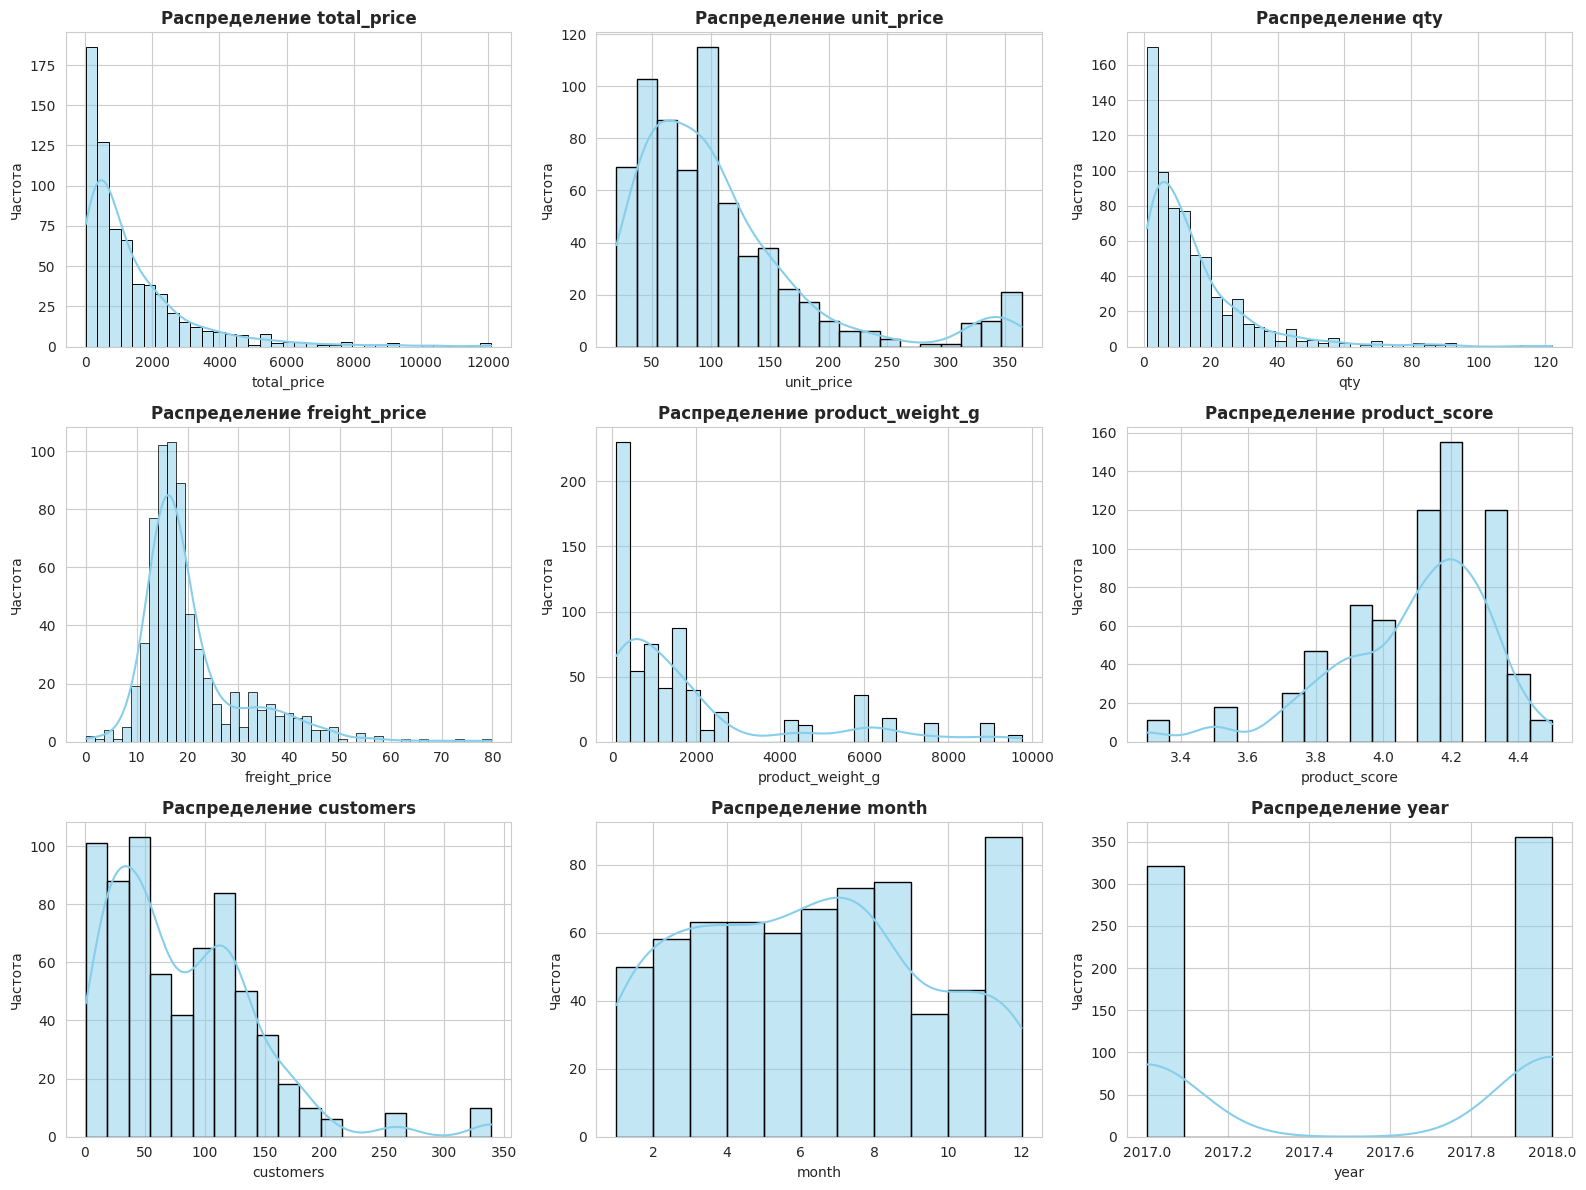

In [6]:
# Визуализация распределений ключевых переменных
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
key_cols = ['total_price', 'unit_price', 'qty', 'freight_price', 
            'product_weight_g', 'product_score', 'customers', 'month', 'year']

for idx, col in enumerate(key_cols):
    ax = axes[idx // 3, idx % 3]
    if col in df.columns:
        sns.histplot(data=df, x=col, kde=True, ax=ax, color='skyblue', edgecolor='black')
        ax.set_title(f'Распределение {col}', fontsize=12, fontweight='bold')
        ax.set_xlabel(col)
        ax.set_ylabel('Частота')
    else:
        ax.text(0.5, 0.5, f'Столбец {col} не найден', ha='center', va='center')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

### 7. Обнаружение выбросов методом box-plot

Диаграмма размаха строится по пяти числам: $\min$, $Q_1$, $Q_2$, $Q_3$, $\max$. Усы ограничены значениями $Q_1 - 1{,}5\,\mathrm{IQR}$ и $Q_3 + 1{,}5\,\mathrm{IQR}$; наблюдения, выходящие за эти границы, классифицируются как потенциальные выбросы.

Выявленные выбросы учитываются в дальнейшем: при оценивании регрессии они проявятся как наблюдения с большими стьюдентизированными остатками и высоким значением расстояния Кука.


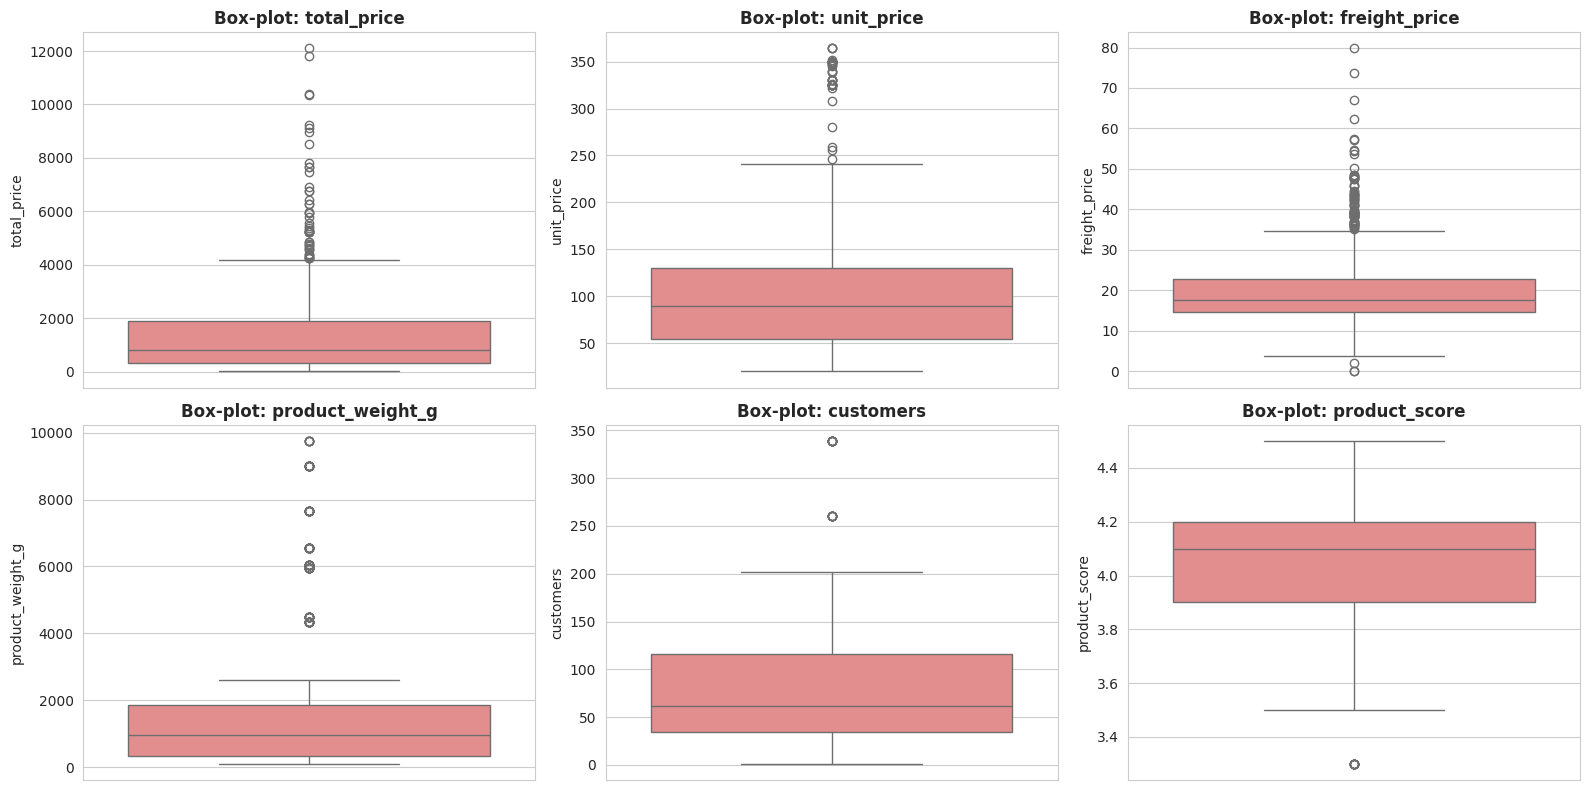

In [7]:
# Box-plots для выявления выбросов
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
box_cols = ['total_price', 'unit_price', 'freight_price', 
            'product_weight_g', 'customers', 'product_score']

for idx, col in enumerate(box_cols):
    ax = axes[idx // 3, idx % 3]
    if col in df.columns:
        sns.boxplot(data=df, y=col, ax=ax, color='lightcoral')
        ax.set_title(f'Box-plot: {col}', fontsize=12, fontweight='bold')
        ax.set_ylabel(col)
    else:
        ax.text(0.5, 0.5, f'Столбец {col} не найден', ha='center', va='center')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

### 8. Корреляционный анализ

Выборочный коэффициент линейной корреляции Пирсона между признаками $X$ и $Y$:

$$r_{XY} = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2 \cdot \sum_{i=1}^{n}(y_i - \bar{y})^2}}, \qquad r_{XY} \in [-1, 1].$$

Корреляционная матрица используется для:

- первичного отбора признаков, связанных с целевой переменной;
- выявления кандидатов на мультиколлинеарность — пары предикторов с $|r|$ близким к 1 фактически дублируют информацию и приводят к плохой обусловленности матрицы $X^\top X$;
- обнаружения утечки целевой переменной — значения корреляции, близкие к $\pm 1$, требуют проверки на предмет функциональной зависимости признака от target.


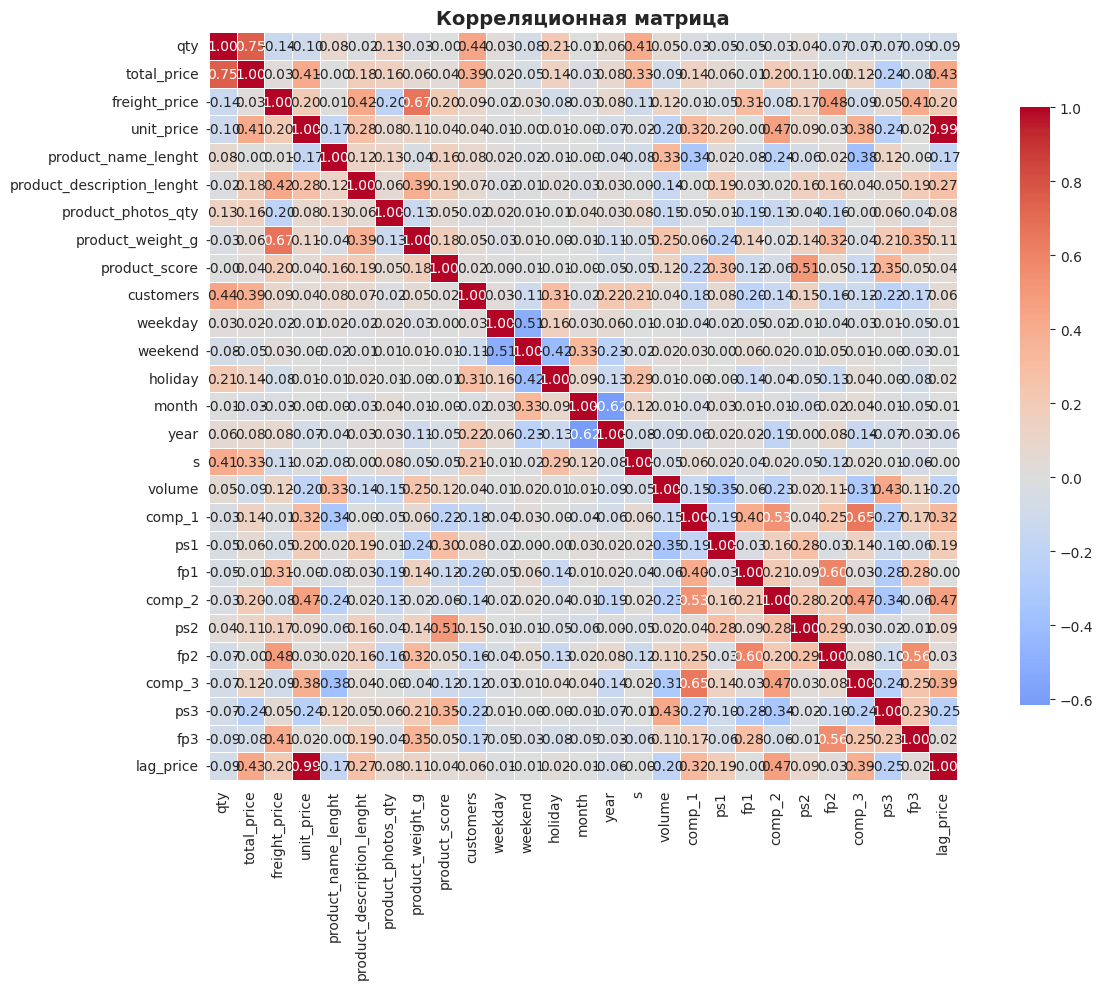


Корреляционная матрица сохранена в переменной corr_matrix


In [8]:
# Корреляционная матрица и heatmap
# Выбираем только числовые столбцы
numeric_df = df.select_dtypes(include=[np.number])

# Вычисляем корреляционную матрицу
corr_matrix = numeric_df.corr()

# Визуализация корреляционной матрицы
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Корреляционная матрица', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nКорреляционная матрица сохранена в переменной corr_matrix")

### 8.1. Сильнейшие корреляционные связи

Для удобства интерпретации выделяем пары переменных с наибольшими по модулю коэффициентами корреляции.

**Обратить внимание:** корреляция `unit_price` и `lag_price` составляет около 0.99, а `total_price` и `qty` — около 0.75. Это следствие структурного тождества $	ext{total\_price} pprox 	ext{unit\_price} \cdot 	ext{qty}$, что означает утечку целевой переменной через `unit_price` и `lag_price`. В основной регрессионной модели эти признаки будут исключены из набора предикторов.


In [9]:
# Анализ самых сильных корреляций
print("\nСамые сильные положительные корреляции:")
print("="*80)
# Получаем верхний треугольник матрицы корреляций
corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        corr_pairs.append({
            'Переменная 1': corr_matrix.columns[i],
            'Переменная 2': corr_matrix.columns[j],
            'Корреляция': corr_matrix.iloc[i, j]
        })

corr_pairs_df = pd.DataFrame(corr_pairs)
corr_pairs_df = corr_pairs_df.sort_values('Корреляция', ascending=False)
print(corr_pairs_df.head(15).to_string())

print("\n\nСамые сильные отрицательные корреляции:")
print("="*80)
print(corr_pairs_df.tail(15).to_string())


Самые сильные положительные корреляции:
      Переменная 1      Переменная 2  Корреляция
97      unit_price         lag_price    0.994453
0              qty       total_price    0.749605
55   freight_price  product_weight_g    0.670689
311         comp_1            comp_3    0.650433
325            fp1               fp2    0.598636
343            fp2               fp3    0.556424
308         comp_1            comp_2    0.532859
192  product_score               ps2    0.506967
70   freight_price               fp2    0.484647
332         comp_2            comp_3    0.472245
91      unit_price            comp_2    0.466459
335         comp_2         lag_price    0.465271
8              qty         customers    0.441547
303         volume               ps3    0.428603
50     total_price         lag_price    0.426256


Самые сильные отрицательные корреляции:
            Переменная 1 Переменная 2  Корреляция
48           total_price          ps3   -0.240526
113  product_name_lenght       co

### 9. Матрица ковариаций

Матрица ковариаций $\Sigma$ содержит на диагонали выборочные дисперсии, а вне диагонали — ковариации $\widehat{\mathrm{Cov}}(X_i, X_j)$. В отличие от корреляционной матрицы она сохраняет масштаб исходных переменных, что затрудняет прямое сравнение, но делает её пригодной для дальнейших построений.

Матрица ковариаций — базовый объект в многомерном статистическом анализе. В частности, она входит в формулу ковариационной матрицы МНК-оценки:

$$\mathrm{Var}(\hat{\beta}) = \sigma^2 (X^\top X)^{-1},$$

и используется в методе главных компонент и в тестах на структуру зависимости.



МАТРИЦА КОВАРИАЦИЙ


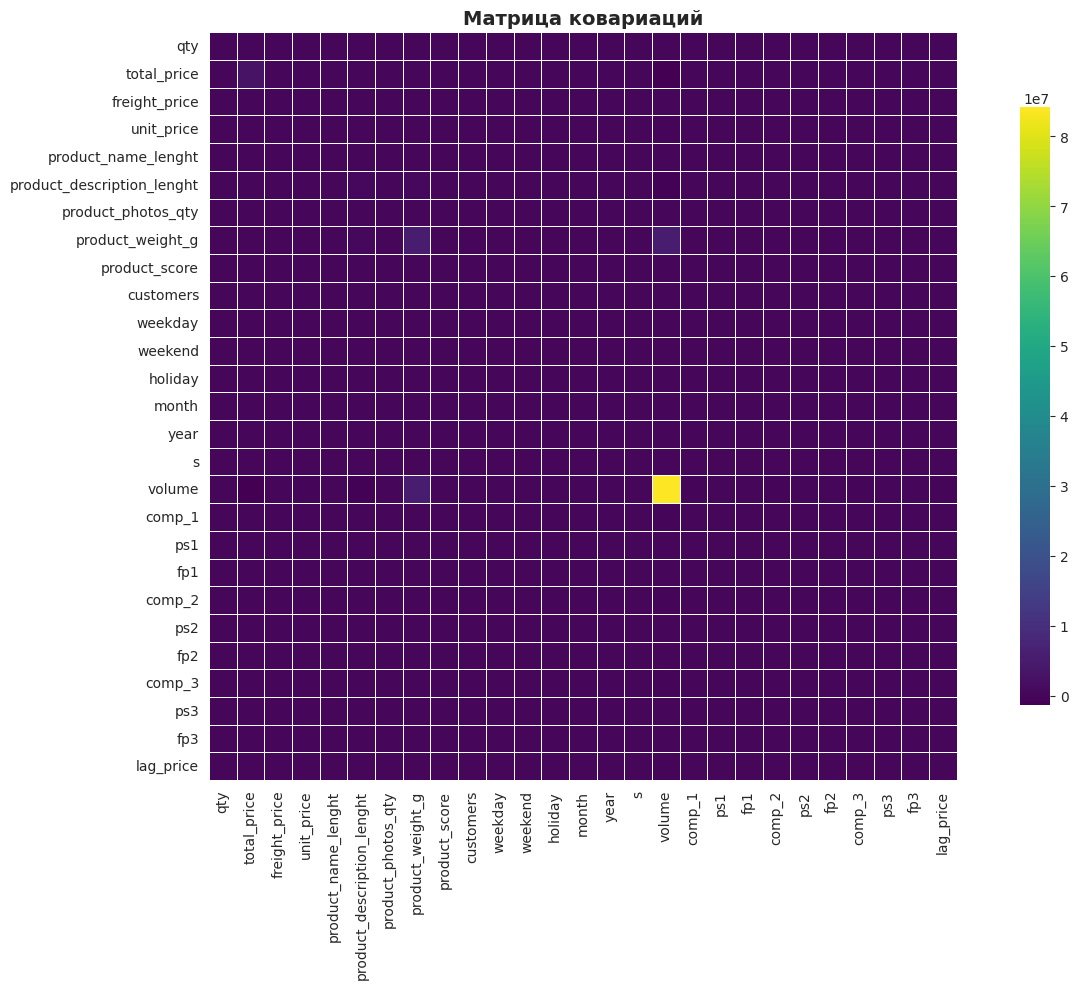


Первые элементы матрицы ковариаций:
                                 qty  total_price  freight_price  unit_price  \
qty                           238.50     19681.42         -21.10     -121.69   
total_price                 19681.42   2890418.55         443.04    52974.04   
freight_price                 -21.10       443.04         101.64      156.42   
unit_price                   -121.69     52974.04         156.42     5803.85   
product_name_lenght            11.64       -41.54           1.27     -122.45   
product_description_lenght   -230.18    195356.44        2795.64    13985.10   
product_photos_qty              2.82       381.43          -2.88        8.33   
product_weight_g            -1205.03    232401.76       15381.71    19575.88   
product_score                  -0.01        14.25           0.47        0.75   
customers                     423.16     40764.83          55.22      205.14   

                            product_name_lenght  product_description_lenght  \
qty

In [10]:
# Матрица ковариаций
print("\nМАТРИЦА КОВАРИАЦИЙ")
print("="*80)
cov_matrix = numeric_df.cov()

# Визуализация матрицы ковариаций
plt.figure(figsize=(14, 10))
sns.heatmap(cov_matrix, annot=False, cmap='viridis', square=True, 
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Матрица ковариаций', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nПервые элементы матрицы ковариаций:")
print(cov_matrix.iloc[:10, :10].round(2))

### 10. Контроль качества данных

Перед переходом к моделированию проверяются:

- **дубликаты строк** — при их наличии нарушается предположение о независимости наблюдений;
- **число уникальных значений ключевых полей** — позволяет оценить структуру панели (товар × период);
- **распределение по категориям товаров** — показывает, насколько сбалансированы группы и стоит ли применять стратифицированные процедуры.


In [11]:
# Проверка на дубли и выбросы
print("\nПРОВЕРКА КАЧЕСТВА ДАННЫХ")
print("="*80)
print(f"Общее количество строк: {len(df)}")
print(f"Количество дублей: {df.duplicated().sum()}")
print(f"Уникальные значения в key_columns:")
for col in ['product_id', 'product_category_name', 'month_year']:
    if col in df.columns:
        print(f"  {col}: {df[col].nunique()}")

print(f"\nКатегории товаров:")
if 'product_category_name' in df.columns:
    print(df['product_category_name'].value_counts().head(10))


ПРОВЕРКА КАЧЕСТВА ДАННЫХ
Общее количество строк: 676
Количество дублей: 0
Уникальные значения в key_columns:
  product_id: 52
  product_category_name: 9
  month_year: 20

Категории товаров:
product_category_name
garden_tools             160
health_beauty            130
watches_gifts            103
computers_accessories     69
bed_bath_table            61
cool_stuff                57
furniture_decor           48
perfumery                 26
consoles_games            22
Name: count, dtype: int64


### Выводы по первичному анализу

1. Выборка содержит $n = 676$ наблюдений по 30 признакам; пропуски и дубликаты отсутствуют, что позволяет применять классические статистические методы без предварительной реконструкции данных.
2. Структура данных — панельная: 52 товара × 20 месяцев, 9 товарных категорий. Это даёт возможность впоследствии контролировать ненаблюдаемую неоднородность на уровне товара.
3. Распределения ключевых числовых переменных (`total_price`, `unit_price`, `qty`, `freight_price`) обладают выраженной правосторонней асимметрией. Логарифмическое преобразование является естественным кандидатом для линеаризации связей и улучшения выполнения предпосылок МНК.
4. По box-plot выявлены потенциальные выбросы в ценовых переменных. Их влияние на оценки коэффициентов будет оценено через стьюдентизированные остатки, leverage и расстояние Кука; при необходимости применяется робастная регрессия.
5. Обнаружены структурные корреляции, близкие к $\pm 1$, указывающие на утечку целевой переменной через признаки `unit_price` и `lag_price`. В основной модели эти признаки исключаются из набора предикторов.
6. Категориальная переменная `product_category_name` (9 уровней) содержит полезную информацию и будет включена в модель через one-hot кодирование.
7. Данные готовы к следующему этапу — подготовке и построению регрессионной модели.

---


---

## Часть II. Подготовка данных к регрессионному анализу

Цель этапа — сформировать матрицу признаков $X$ и вектор отклика $y$, удовлетворяющие требованиям классической линейной регрессии.

Последовательность шагов:

1. исключение признаков, дающих утечку целевой переменной;
2. one-hot кодирование категориальной переменной `product_category_name`;
3. логарифмическое преобразование целевой переменной и сильно скошенных предикторов;
4. формирование итоговой матрицы признаков для подачи в модель.

### II.1. Исключение признаков с утечкой

Переменная `total_price` связана с рядом признаков структурным тождеством

$$\text{total\_price} \approx \text{unit\_price} \cdot \text{qty}.$$

Признаки, участвующие в этом тождестве, необходимо исключить из набора предикторов:

- `unit_price` — цена за единицу; корреляция с `lag_price` составляет $r \approx 0{,}994$;
- `lag_price` — цена единицы в предыдущий период (по сути близкая копия `unit_price`);
- `qty` — количество единиц в заказе; второй сомножитель тождества.

При их сохранении коэффициент детерминации $R^2$ искусственно раздувается, а оценки коэффициентов при остальных предикторах теряют содержательную интерпретацию: модель воспроизводит тождество, а не объясняет вариацию цены через факторы.

Дополнительно удаляются нечисловые идентификаторы `product_id` и `month_year` — они не несут информации для стандартной линейной модели, однако могут быть использованы при расширении работы до панельного анализа.

In [12]:
# Копия исходного датасета для модельной подготовки
df_model = df.copy()

# Идентификаторы и признаки с утечкой целевой переменной
id_cols = ['product_id', 'month_year']
leaky_cols = ['unit_price', 'lag_price', 'qty']

df_model = df_model.drop(columns=id_cols + leaky_cols)

print("Исключено признаков с утечкой:")
for c in leaky_cols:
    print(f"  - {c}")
print("\nИсключено идентификаторов:")
for c in id_cols:
    print(f"  - {c}")
print(f"\nФорма датасета до:    {df.shape}")
print(f"Форма датасета после: {df_model.shape}")

Исключено признаков с утечкой:
  - unit_price
  - lag_price
  - qty

Исключено идентификаторов:
  - product_id
  - month_year

Форма датасета до:    (676, 30)
Форма датасета после: (676, 25)


### II.2. Кодирование категориальной переменной

Переменная `product_category_name` принимает 9 значений. Для включения в линейную модель применяется **one-hot кодирование** с опцией `drop_first=True`: одна категория отбрасывается и становится базовой, оставшиеся 8 превращаются в бинарные dummy-переменные.

Отбрасывание одной категории необходимо во избежание **ловушки дамми-переменных** — полной линейной зависимости между всеми 9 дамми-столбцами и константой, приводящей к вырожденности матрицы $X^\top X$ и невозможности вычислить МНК-оценку.

Интерпретация коэффициентов: $\hat{\beta}_{\text{cat}\_j}$ — разница в условном среднем $\ln \text{total\_price}$ между категорией $j$ и базовой категорией при прочих равных.

In [13]:
# One-hot кодирование категории товара
n_categories_before = df_model['product_category_name'].nunique()

df_model = pd.get_dummies(
    df_model,
    columns=['product_category_name'],
    prefix='cat',
    drop_first=True,
    dtype=int
)

cat_cols = [c for c in df_model.columns if c.startswith('cat_')]

print(f"Число категорий в исходной переменной: {n_categories_before}")
print(f"Создано dummy-переменных: {len(cat_cols)}")
print(f"(одна категория отброшена как базовая во избежание ловушки дамми)")
print(f"\nСозданные dummy-переменные:")
for c in cat_cols:
    print(f"  - {c}")
print(f"\nФорма датасета: {df_model.shape}")

Число категорий в исходной переменной: 9
Создано dummy-переменных: 8
(одна категория отброшена как базовая во избежание ловушки дамми)

Созданные dummy-переменные:
  - cat_computers_accessories
  - cat_consoles_games
  - cat_cool_stuff
  - cat_furniture_decor
  - cat_garden_tools
  - cat_health_beauty
  - cat_perfumery
  - cat_watches_gifts

Форма датасета: (676, 32)


### II.3. Логарифмическое преобразование

Для количественных переменных с сильной правосторонней асимметрией применяется преобразование $x \mapsto \ln x$ (при $x > 0$).

**Цели преобразования:**

1. приближение условного распределения ошибки к нормальному — необходимое условие для корректности $t$- и $F$-тестов;
2. стабилизация дисперсии ошибки — снижение риска гетероскедастичности;
3. линеаризация мультипликативных связей: модель вида $y = A \cdot x_1^{\beta_1} \cdot x_2^{\beta_2} \cdot e^{\varepsilon}$ после логарифмирования становится линейной: $\ln y = \ln A + \beta_1 \ln x_1 + \beta_2 \ln x_2 + \varepsilon$.

**Критерий отбора.** Логарифмируются непрерывные переменные с выборочным коэффициентом асимметрии $|\widehat{g_1}| > 1$. Бинарные (`weekend`, `holiday`), дискретные временные (`weekday`, `month`, `year`) и dummy-признаки преобразованию не подлежат.

Коэффициент асимметрии:

$$\widehat{g_1} = \frac{\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^3}{\left(\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^2\right)^{3/2}}.$$

In [14]:
# Переменные, НЕ подлежащие логарифмированию
binary_cols = ['weekend', 'holiday']
time_cols = ['weekday', 'month', 'year']
excluded_from_log = cat_cols + binary_cols + time_cols

# Непрерывные числовые переменные
continuous_cols = [c for c in df_model.select_dtypes(include=[np.number]).columns
                   if c not in excluded_from_log]

# Выборочный коэффициент асимметрии
skew_table = df_model[continuous_cols].skew().sort_values(ascending=False)

print("Коэффициент асимметрии непрерывных переменных:")
print("="*60)
print(skew_table.round(3).to_string())

threshold = 1.0
to_log = skew_table[skew_table.abs() > threshold].index.tolist()

print(f"\nПорог отбора: |skew| > {threshold}")
print(f"Кандидатов на логарифмирование: {len(to_log)}")
for c in to_log:
    print(f"  - {c:30s} skew = {skew_table[c]:+.3f}")

Коэффициент асимметрии непрерывных переменных:
total_price                   2.614
s                             2.412
fp3                           2.191
product_photos_qty            1.889
freight_price                 1.846
product_weight_g              1.786
fp2                           1.689
fp1                           1.644
comp_2                        1.638
product_description_lenght    1.554
customers                     1.403
comp_1                        1.369
comp_3                        1.219
volume                        1.159
ps3                          -0.158
product_name_lenght          -0.530
ps1                          -0.880
product_score                -1.032
ps2                          -1.661

Порог отбора: |skew| > 1.0
Кандидатов на логарифмирование: 16
  - total_price                    skew = +2.614
  - s                              skew = +2.412
  - fp3                            skew = +2.191
  - product_photos_qty             skew = +1.889
  - freigh

In [15]:
# Применяем логарифмирование к отобранным переменным
for col in to_log:
    log_col = f'log_{col}'
    if (df_model[col] > 0).all():
        df_model[log_col] = np.log(df_model[col])
    else:
        df_model[log_col] = np.log1p(df_model[col])

# Сравнение: асимметрия до и после
log_cols_created = [f'log_{c}' for c in to_log]
skew_after = df_model[log_cols_created].skew()

comparison = pd.DataFrame({
    'Переменная': to_log,
    'Skew до':    [skew_table[c] for c in to_log],
    'Skew после': [skew_after[f'log_{c}'] for c in to_log],
})
print("Асимметрия до и после логарифмирования:")
print("="*70)
print(comparison.round(3).to_string(index=False))

# Удаляем исходные версии логарифмированных переменных
df_model = df_model.drop(columns=to_log)
print(f"\nФорма датасета после преобразования: {df_model.shape}")

Асимметрия до и после логарифмирования:
                Переменная  Skew до  Skew после
               total_price    2.614      -0.261
                         s    2.412      -0.501
                       fp3    2.191       0.465
        product_photos_qty    1.889       0.794
             freight_price    1.846      -0.571
          product_weight_g    1.786       0.109
                       fp2    1.689       0.460
                       fp1    1.644      -4.150
                    comp_2    1.638      -0.182
product_description_lenght    1.554       0.276
                 customers    1.403      -0.964
                    comp_1    1.369      -0.334
                    comp_3    1.219       0.316
                    volume    1.159      -0.186
             product_score   -1.032      -1.230
                       ps2   -1.661      -1.869

Форма датасета после преобразования: (676, 32)


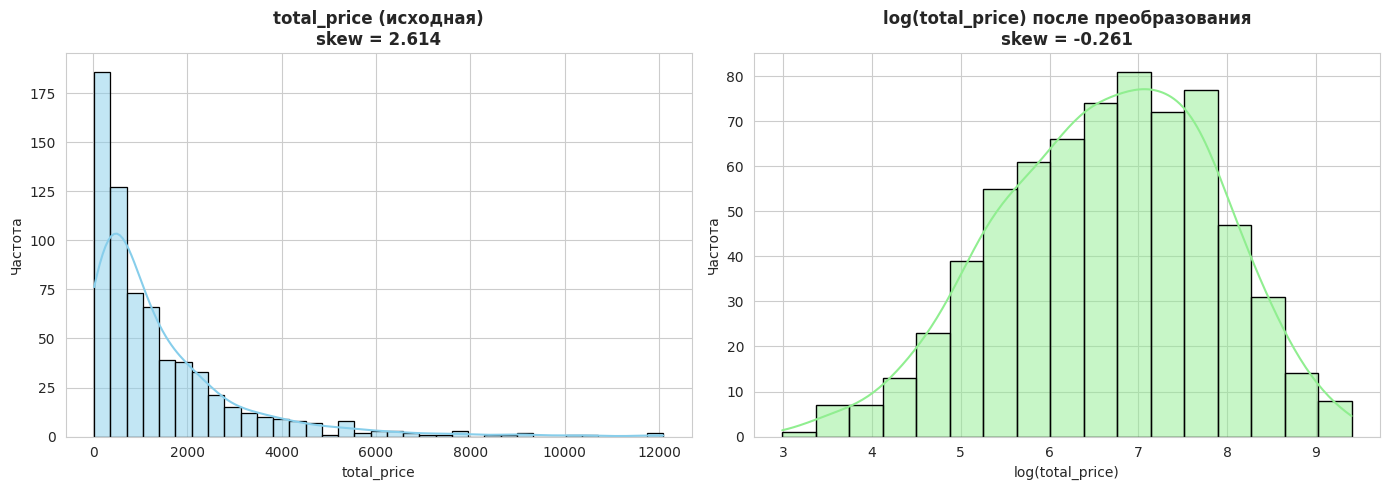

In [16]:
# Визуальное сравнение распределения целевой переменной до и после логарифмирования
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='total_price', kde=True, ax=axes[0],
             color='skyblue', edgecolor='black')
axes[0].set_title(f'total_price (исходная)\nskew = {df["total_price"].skew():.3f}',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('total_price')
axes[0].set_ylabel('Частота')

sns.histplot(data=df_model, x='log_total_price', kde=True, ax=axes[1],
             color='lightgreen', edgecolor='black')
axes[1].set_title(f'log(total_price) после преобразования\nskew = {df_model["log_total_price"].skew():.3f}',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('log(total_price)')
axes[1].set_ylabel('Частота')

plt.tight_layout()
plt.show()

### II.4. Итоговая матрица признаков

Из подготовленного датасета выделяются:

- **вектор отклика** $y = \ln \text{total\_price}$;
- **матрица признаков** $X$ — все остальные переменные.

Итоговый набор признаков включает:

- непрерывные количественные переменные (возможно, после логарифмирования);
- бинарные признаки `weekend`, `holiday`;
- дискретные временные `weekday`, `month`, `year` (при необходимости будут дополнительно преобразованы в дамми на этапе диагностики);
- 8 dummy-переменных товарных категорий.

Объекты `X_model` и `y_model` используются на следующем этапе — при построении регрессионной модели методом наименьших квадратов через `statsmodels`.

In [17]:
# Формирование матрицы признаков и вектора отклика
y_model = df_model['log_total_price']
X_model = df_model.drop(columns=['log_total_price'])

print("="*60)
print("ИТОГОВАЯ МАТРИЦА ПРИЗНАКОВ")
print("="*60)
print(f"Форма X_model: {X_model.shape}")
print(f"Форма y_model: {y_model.shape}")
print(f"\nЦелевая переменная: y = log(total_price)")
print(f"Число наблюдений: n = {len(y_model)}")
print(f"Число признаков:  k = {X_model.shape[1]}")
print(f"\nСписок признаков:")
for c in X_model.columns:
    print(f"  - {c}")

ИТОГОВАЯ МАТРИЦА ПРИЗНАКОВ
Форма X_model: (676, 31)
Форма y_model: (676,)

Целевая переменная: y = log(total_price)
Число наблюдений: n = 676
Число признаков:  k = 31

Список признаков:
  - product_name_lenght
  - weekday
  - weekend
  - holiday
  - month
  - year
  - ps1
  - ps3
  - cat_computers_accessories
  - cat_consoles_games
  - cat_cool_stuff
  - cat_furniture_decor
  - cat_garden_tools
  - cat_health_beauty
  - cat_perfumery
  - cat_watches_gifts
  - log_s
  - log_fp3
  - log_product_photos_qty
  - log_freight_price
  - log_product_weight_g
  - log_fp2
  - log_fp1
  - log_comp_2
  - log_product_description_lenght
  - log_customers
  - log_comp_1
  - log_comp_3
  - log_volume
  - log_product_score
  - log_ps2


---

## Часть III. Базовая модель множественной линейной регрессии (МНК)

На подготовленных объектах $X$ (`X_model`) и $y = \ln(\text{total\_price})$ (`y_model`)
строится **классическая линейная модель**

$$
y_i = \beta_0 + \beta_1 x_{i1} + \dots + \beta_k x_{ik} + \varepsilon_i,
\qquad i = 1,\dots,n,
$$

или в матричной форме $\mathbf{y} = X\boldsymbol{\beta} + \boldsymbol{\varepsilon}$,
где $X$ — матрица регрессоров с добавленным столбцом единиц для свободного члена.

**Предпосылки классической линейной модели (КЛМ).**

1. *Линейность по параметрам.*
2. *Полный ранг:* $\operatorname{rank}(X) = k+1$ (отсутствие строгой мультиколлинеарности).
3. *Экзогенность:* $\mathbb{E}[\varepsilon_i \mid X] = 0$.
4. *Гомоскедастичность и некоррелированность ошибок:* $\operatorname{Var}(\boldsymbol{\varepsilon} \mid X) = \sigma^2 I_n$.
5. *Нормальность ошибок (для точного вывода):* $\boldsymbol{\varepsilon} \mid X \sim \mathcal{N}(0, \sigma^2 I_n)$.

При выполнении (1)–(4) **МНК-оценка**

$$
\widehat{\boldsymbol{\beta}} = (X^\top X)^{-1} X^\top \mathbf{y}
$$

является несмещённой и эффективной в классе линейных несмещённых оценок (теорема Гаусса–Маркова).
Дополнительно (5) обеспечивает точные распределения t- и F-статистик.

В этой главе оценки и диагностика реализуются через `statsmodels.OLS`,
поскольку требуются стандартные ошибки $\widehat{\operatorname{SE}}(\widehat{\beta}_j)$,
t-статистики, p-значения, F-тест и доверительные интервалы — всё это даёт
регрессионный summary библиотеки `statsmodels`.


### III.1. Спецификация модели и подгонка МНК

Регрессионная матрица $X$ дополняется столбцом из единиц, после чего
оценки коэффициентов получаются по формуле $\widehat{\beta} = (X^\top X)^{-1} X^\top y$.
Это делает функция `sm.add_constant`, а сама подгонка — `sm.OLS(y, X).fit()`.

Спецификация модели:

* **Отклик:** $y = \ln(\text{total\_price})$.
* **Регрессоры:** все переменные `X_model` — лог-преобразованные количественные признаки,
  бинарные/временные индикаторы и dummy-переменные товарных категорий.
* **Параметров оценивается:** $k+1$ (включая свободный член).


In [18]:
import statsmodels.api as sm

# Добавляем столбец единиц для свободного члена
X_design = sm.add_constant(X_model, has_constant='add')

# Подгонка МНК
ols_model = sm.OLS(y_model, X_design)
ols_results = ols_model.fit()

n, k_plus_1 = X_design.shape
k = k_plus_1 - 1

print(f"Размер выборки:           n = {n}")
print(f"Число регрессоров:        k = {k} (+ свободный член)")
print(f"Число степеней свободы:   df_resid = {int(ols_results.df_resid)}")
print(f"Ранг матрицы регрессоров: {int(ols_results.df_model + 1)}")


Размер выборки:           n = 676
Число регрессоров:        k = 31 (+ свободный член)
Число степеней свободы:   df_resid = 644
Ранг матрицы регрессоров: 32


### III.2. Регрессионная таблица

Полный отчёт `statsmodels` приводится ниже. Колонки:

* `coef` — оценки $\widehat{\beta}_j$;
* `std err` — стандартные ошибки $\widehat{\operatorname{SE}}(\widehat{\beta}_j) = \sqrt{\widehat{\sigma}^2 \cdot \big[(X^\top X)^{-1}\big]_{jj}}$, где $\widehat{\sigma}^2 = \frac{1}{n-k-1}\sum \widehat{\varepsilon}_i^2$;
* `t` — статистика $t_j = \widehat{\beta}_j / \widehat{\operatorname{SE}}(\widehat{\beta}_j)$, при $H_0: \beta_j = 0$ имеет распределение Стьюдента $t_{n-k-1}$;
* `P>|t|` — двустороннее p-значение;
* `[0.025, 0.975]` — асимптотический 95%-ный доверительный интервал
  $\widehat{\beta}_j \pm t_{1-\alpha/2,\, n-k-1} \cdot \widehat{\operatorname{SE}}(\widehat{\beta}_j)$.


In [19]:
print(ols_results.summary())


                            OLS Regression Results                            
Dep. Variable:        log_total_price   R-squared:                       0.559
Model:                            OLS   Adj. R-squared:                  0.538
Method:                 Least Squares   F-statistic:                     26.35
Date:                Sat, 09 May 2026   Prob (F-statistic):           6.28e-94
Time:                        15:01:14   Log-Likelihood:                -802.31
No. Observations:                 676   AIC:                             1669.
Df Residuals:                     644   BIC:                             1813.
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

### III.3. F-тест значимости модели в целом

Нулевая гипотеза: все $\beta_1,\dots,\beta_k = 0$ (модель без объяснительной силы).
Альтернатива: хотя бы один коэффициент отличен от нуля.

Статистика теста при $H_0$ имеет распределение Фишера $F(k,\, n-k-1)$:

$$
F = \frac{R^2 / k}{(1-R^2)/(n-k-1)}.
$$

Малое p-значение свидетельствует против $H_0$ — модель в целом значима.


In [20]:
f_stat = ols_results.fvalue
f_pvalue = ols_results.f_pvalue
df_model = int(ols_results.df_model)
df_resid = int(ols_results.df_resid)

print("F-тест значимости модели в целом")
print("-" * 60)
print(f"H0:  все beta_j = 0 (j = 1, ..., k)")
print(f"H1:  хотя бы один beta_j != 0")
print()
print(f"Статистика F        = {f_stat:.4f}")
print(f"Степени свободы     = ({df_model}, {df_resid})")
print(f"p-значение          = {f_pvalue:.3e}")

alpha = 0.05
verdict = "отвергаем" if f_pvalue < alpha else "не отвергаем"
print(f"\nПри alpha = {alpha} нулевая гипотеза {verdict}.")


F-тест значимости модели в целом
------------------------------------------------------------
H0:  все beta_j = 0 (j = 1, ..., k)
H1:  хотя бы один beta_j != 0

Статистика F        = 26.3513
Степени свободы     = (31, 644)
p-значение          = 6.275e-94

При alpha = 0.05 нулевая гипотеза отвергаем.


### III.4. Качество подгонки модели

Используются стандартные показатели:

* $R^2 = 1 - \dfrac{\mathrm{RSS}}{\mathrm{TSS}}$ — доля объяснённой дисперсии отклика;
* скорректированный $R^2_{\mathrm{adj}} = 1 - (1-R^2)\dfrac{n-1}{n-k-1}$ — учитывает число регрессоров;
* информационные критерии $\mathrm{AIC} = -2\ell + 2(k+1)$ и $\mathrm{BIC} = -2\ell + (k+1)\ln n$
  (используются для сравнения вложенных и невложенных спецификаций);
* остаточная дисперсия $\widehat{\sigma}^2 = \mathrm{RSS}/(n-k-1)$.


In [21]:
rss = float((ols_results.resid ** 2).sum())
tss = float(((y_model - y_model.mean()) ** 2).sum())
sigma2_hat = rss / df_resid

fit_table = pd.DataFrame({
    "Показатель": [
        "R^2",
        "R^2 скорр.",
        "Лог-правдоподобие",
        "AIC",
        "BIC",
        "RSS",
        "TSS",
        "sigma^2 (оценка)",
        "sigma (оценка)",
    ],
    "Значение": [
        round(ols_results.rsquared, 4),
        round(ols_results.rsquared_adj, 4),
        round(ols_results.llf, 2),
        round(ols_results.aic, 2),
        round(ols_results.bic, 2),
        round(rss, 4),
        round(tss, 4),
        round(sigma2_hat, 6),
        round(np.sqrt(sigma2_hat), 6),
    ],
})

print("Показатели качества подгонки:")
print(fit_table.to_string(index=False))


Показатели качества подгонки:
       Показатель    Значение
              R^2    0.559200
       R^2 скорр.    0.538000
Лог-правдоподобие -802.310000
              AIC 1668.620000
              BIC 1813.140000
              RSS  424.969100
              TSS  964.027500
 sigma^2 (оценка)    0.659890
   sigma (оценка)    0.812336


### III.5. Доверительные интервалы и сводная таблица коэффициентов

Для каждого коэффициента строится 95%-ный t-доверительный интервал

$$
\widehat{\beta}_j \pm t_{1-\alpha/2,\, n-k-1} \cdot \widehat{\operatorname{SE}}(\widehat{\beta}_j),
\qquad \alpha = 0.05.
$$

В таблице ниже коэффициенты упорядочены по p-значению, чтобы наглядно
выделить статистически значимые предикторы.


In [22]:
ci = ols_results.conf_int(alpha=0.05)
ci.columns = ["CI 2.5%", "CI 97.5%"]

coef_table = pd.DataFrame({
    "coef": ols_results.params,
    "std_err": ols_results.bse,
    "t": ols_results.tvalues,
    "p_value": ols_results.pvalues,
}).join(ci)

# Помечаем уровень значимости
def stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    if p < 0.10:
        return "."
    return ""


coef_table["sig"] = coef_table["p_value"].apply(stars)
coef_table = coef_table.sort_values("p_value")

print("Коэффициенты МНК (отсортированы по p-значению)")
print("Условные обозначения: *** p<0.001, ** p<0.01, * p<0.05, . p<0.10")
print()
print(coef_table.round(4).to_string())

# Список значимых коэффициентов на уровне 0.05
sig_05 = coef_table[coef_table["p_value"] < 0.05].index.tolist()
print(f"\nЗначимых при alpha = 0.05: {len(sig_05)} из {len(coef_table)}")


Коэффициенты МНК (отсортированы по p-значению)
Условные обозначения: *** p<0.001, ** p<0.01, * p<0.05, . p<0.10

                                    coef   std_err        t  p_value   CI 2.5%  CI 97.5%  sig
log_s                             0.6626    0.0443  14.9579   0.0000    0.5756    0.7496  ***
log_customers                     0.4737    0.0518   9.1374   0.0000    0.3719    0.5754  ***
log_volume                        0.3375    0.0630   5.3579   0.0000    0.2138    0.4612  ***
log_product_weight_g              0.2827    0.0532   5.3106   0.0000    0.1782    0.3872  ***
cat_garden_tools                 -0.9723    0.2031  -4.7876   0.0000   -1.3710   -0.5735  ***
log_product_photos_qty            0.2843    0.0673   4.2267   0.0000    0.1522    0.4163  ***
log_comp_3                        0.5717    0.1455   3.9278   0.0001    0.2859    0.8575  ***
cat_cool_stuff                   -0.6917    0.2650  -2.6102   0.0093   -1.2120   -0.1713   **
cat_consoles_games                0.6828 

### III.6. Содержательная интерпретация коэффициентов

Поскольку отклик логарифмирован, $y = \ln(\text{total\_price})$, коэффициенты интерпретируются так:

* **полу-эластичность** (для нелогарифмированных $x_j$): увеличение признака на $\Delta x_j = 1$ единицу
  изменяет цену приблизительно на $100 \cdot (e^{\widehat{\beta}_j} - 1)\,\%$,
  при малых $\widehat{\beta}_j$ это $\approx 100\widehat{\beta}_j\,\%$;
* **эластичность** (если предиктор тоже логарифмирован, $x_j = \ln \tilde{x}_j$): $\widehat{\beta}_j$ —
  эластичность $\text{total\_price}$ по $\tilde{x}_j$;
* **dummy товарных категорий**: $\widehat{\beta}_j$ — отклонение условного среднего $\ln(\text{total\_price})$
  от базовой категории при прочих равных, т.е. соответствующая категория дороже/дешевле
  базовой в $e^{\widehat{\beta}_j}$ раз.

Ниже выводится сводка по всем значимым (на уровне $\alpha = 0.05$) коэффициентам с переводом эффекта в проценты.


In [23]:
log_features = {c for c in X_model.columns if c.startswith("log_")}

rows = []
for name in sig_05:
    if name == "const":
        continue
    beta = ols_results.params[name]
    p = ols_results.pvalues[name]
    if name in log_features:
        kind = "эластичность"
        effect = f"{beta:+.3f} (% на 1% роста)"
    else:
        kind = "полу-эластичность"
        pct = (np.exp(beta) - 1.0) * 100.0
        effect = f"{pct:+.2f}% на +1 ед."
    rows.append({
        "Признак": name,
        "beta_hat": round(beta, 4),
        "Тип эффекта": kind,
        "Эффект на total_price": effect,
        "p-value": f"{p:.2e}",
    })

interp_table = pd.DataFrame(rows)
print("Содержательная интерпретация значимых коэффициентов (alpha = 0.05)")
print(interp_table.to_string(index=False))


Содержательная интерпретация значимых коэффициентов (alpha = 0.05)
               Признак  beta_hat       Тип эффекта  Эффект на total_price  p-value
                 log_s    0.6626      эластичность +0.663 (% на 1% роста) 1.23e-43
         log_customers    0.4737      эластичность +0.474 (% на 1% роста) 8.22e-19
            log_volume    0.3375      эластичность +0.338 (% на 1% роста) 1.17e-07
  log_product_weight_g    0.2827      эластичность +0.283 (% на 1% роста) 1.51e-07
      cat_garden_tools   -0.9723 полу-эластичность      -62.18% на +1 ед. 2.10e-06
log_product_photos_qty    0.2843      эластичность +0.284 (% на 1% роста) 2.71e-05
            log_comp_3    0.5717      эластичность +0.572 (% на 1% роста) 9.50e-05
        cat_cool_stuff   -0.6917 полу-эластичность      -49.93% на +1 ед. 9.26e-03
    cat_consoles_games    0.6828 полу-эластичность      +97.95% на +1 ед. 3.79e-02


### III.7. Промежуточные выводы по базовой модели

* Получены **оценки МНК** для всех $k+1$ параметров; модель оценена на полной выборке без разбиения
  на train/test, поскольку основная цель главы — статистический вывод о коэффициентах,
  а не оценка предсказательной способности.
* **F-тест** показывает значимость модели в целом, **t-тесты** — отдельных коэффициентов.
* **Доверительные интервалы** построены в предположении нормальности ошибок и
  гомоскедастичности; их адекватность будет дополнительно проверена в Главе 2 (диагностика предпосылок)
  и сопоставлена с **bootstrap**-интервалами в Главе 4.
* На следующем шаге проводится формальная проверка предпосылок КЛМ:
  нормальность остатков (§2.1), гомоскедастичность (§2.2), независимость ошибок (§2.3),
  мультиколлинеарность (§2.4), выявление выбросов и влиятельных наблюдений (§2.5).


---

## Часть IV. Диагностика предпосылок классической линейной модели

В Части III получены оценки МНК и проведён первичный статистический вывод
в предположении выполнения предпосылок КЛМ. В этой главе предпосылки
проверяются формально:

| Предпосылка | Проверяется в |
|---|---|
| Нормальность ошибок | §IV.1 |
| Гомоскедастичность | §IV.2 |
| Независимость (отсутствие автокорреляции) | §IV.3 |
| Отсутствие мультиколлинеарности | §IV.4 |
| Отсутствие сильно влияющих наблюдений | §IV.5 |

По итогу формируется список нарушений, на основании которого в Главе 3
будут применены альтернативные методы оценивания (WLS, Ridge, Lasso, Huber).
Все тесты проводятся на остатках $\widehat{\varepsilon}_i = y_i - \widehat{y}_i$
из модели `ols_results`.


In [24]:
# Базовые объекты для всей главы IV
resid = ols_results.resid              # остатки eps_hat_i
fitted = ols_results.fittedvalues      # предсказания y_hat_i
infl = ols_results.get_influence()     # объект диагностики влияния
n_obs = int(ols_results.nobs)
k_full = int(ols_results.df_model)     # число регрессоров без константы

# Стьюдентизированные внутренне-нормированные и внешне-нормированные остатки
resid_studentized_internal = infl.resid_studentized_internal
resid_studentized_external = infl.resid_studentized_external

# Базовый итоговый словарь по диагностике (заполняется по мере проверок)
diagnostic_summary = {}

print(f"Размер выборки:        n = {n_obs}")
print(f"Число регрессоров:     k = {k_full}")
print(f"Степени свободы рез.:  {n_obs - k_full - 1}")
print(f"Сумма остатков:        {resid.sum():.4e}  (должна быть ~ 0)")
print(f"Среднее остатков:      {resid.mean():.4e}")


Размер выборки:        n = 676
Число регрессоров:     k = 31
Степени свободы рез.:  644
Сумма остатков:        -3.1163e-10  (должна быть ~ 0)
Среднее остатков:      -4.6099e-13


### IV.1. Нормальность остатков

Точность $t$- и $F$-тестов в КЛМ опирается на $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$.
При $n = 676$ ЦПТ обеспечивает асимптотическую нормальность $\widehat{\beta}$
даже без нормальности ошибок, но конечная выборочная точность зависит от хвостов.

Применяются три формальных теста и графический анализ.

**1. Тест Шапиро–Уилка.** Статистика $W$ оценивает, насколько порядковые статистики
выборки соответствуют ожидаемым значениям при нормальном распределении:
$$
W = \frac{\big(\sum_i a_i \widehat{\varepsilon}_{(i)}\big)^2}{\sum_i (\widehat{\varepsilon}_i - \bar{\widehat{\varepsilon}})^2}.
$$
$H_0$: ошибки нормальны. Малое $p$ — отвержение нормальности.

**2. Тест Жарка–Бера.** Использует выборочные асимметрию $\widehat{S}$ и эксцесс $\widehat{K}$:
$$
JB = \frac{n}{6}\Big(\widehat{S}^2 + \tfrac{1}{4}(\widehat{K}-3)^2\Big) \xrightarrow{d} \chi^2_2.
$$

**3. Тест Колмогорова–Смирнова** на согласие с $\mathcal{N}(0, \widehat{\sigma}^2)$.
Используется как вспомогательный — он менее чувствителен в хвостах, но даёт
независимое подтверждение.

Графика: гистограмма с наложенной плотностью $\mathcal{N}(0, \widehat{\sigma}^2)$ и Q–Q plot.


In [25]:
from scipy import stats as sps
from statsmodels.stats.stattools import jarque_bera

# Шапиро-Уилк
sw_stat, sw_p = sps.shapiro(resid)
# Жарка-Бера (statsmodels возвращает (JB, p, skew, kurtosis))
jb_stat, jb_p, jb_skew, jb_kurt = jarque_bera(resid)
# Колмогоров-Смирнов с подогнанной нормальной
ks_stat, ks_p = sps.kstest(resid, 'norm', args=(resid.mean(), resid.std(ddof=1)))

normality_table = pd.DataFrame({
    "Тест": ["Шапиро–Уилка", "Жарка–Бера", "Колмогоров–Смирнов"],
    "Статистика": [round(sw_stat, 4), round(jb_stat, 4), round(ks_stat, 4)],
    "p-значение": [f"{sw_p:.3e}", f"{jb_p:.3e}", f"{ks_p:.3e}"],
    "Решение (alpha=0.05)": [
        "H0 отвергаем" if sw_p < 0.05 else "H0 не отвергаем",
        "H0 отвергаем" if jb_p < 0.05 else "H0 не отвергаем",
        "H0 отвергаем" if ks_p < 0.05 else "H0 не отвергаем",
    ],
})

print("Тесты на нормальность остатков (H0: остатки нормальны)")
print(normality_table.to_string(index=False))
print()
print(f"Выборочная асимметрия остатков (skew):  {jb_skew:+.4f}")
print(f"Выборочный эксцесс остатков (kurtosis): {jb_kurt:.4f}")

diagnostic_summary["normality"] = {
    "shapiro_p": sw_p,
    "jb_p": jb_p,
    "ks_p": ks_p,
    "violated": min(sw_p, jb_p, ks_p) < 0.05,
}


Тесты на нормальность остатков (H0: остатки нормальны)
              Тест  Статистика p-значение Решение (alpha=0.05)
      Шапиро–Уилка      0.9549  1.577e-13         H0 отвергаем
        Жарка–Бера    100.5857  1.439e-22         H0 отвергаем
Колмогоров–Смирнов      0.0750  9.474e-04         H0 отвергаем

Выборочная асимметрия остатков (skew):  -0.8627
Выборочный эксцесс остатков (kurtosis): 3.7707


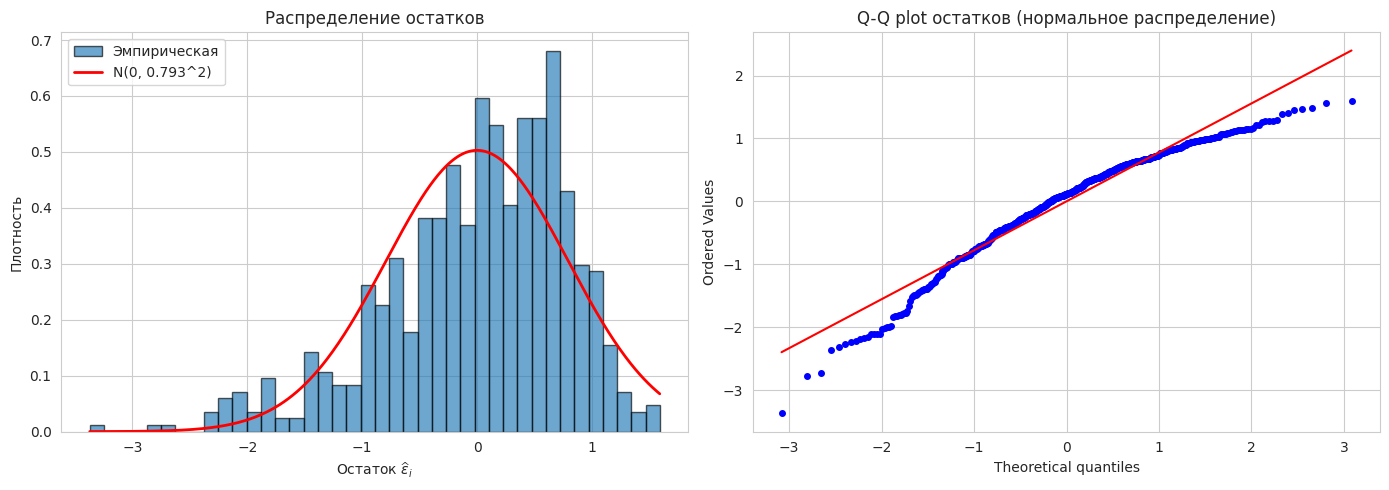

In [26]:
import scipy.stats as sps

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Гистограмма остатков с теоретической нормальной плотностью
sigma_hat = resid.std(ddof=1)
xs = np.linspace(resid.min(), resid.max(), 400)
axes[0].hist(resid, bins=40, density=True, alpha=0.65, edgecolor='k', label='Эмпирическая')
axes[0].plot(xs, sps.norm.pdf(xs, loc=0, scale=sigma_hat), 'r-', lw=2,
             label=f'N(0, {sigma_hat:.3f}^2)')
axes[0].set_xlabel('Остаток $\\widehat{\\varepsilon}_i$')
axes[0].set_ylabel('Плотность')
axes[0].set_title('Распределение остатков')
axes[0].legend()

# (b) Q-Q plot
sps.probplot(resid, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot остатков (нормальное распределение)')
axes[1].get_lines()[0].set_markersize(4)

plt.tight_layout()
plt.show()


### IV.2. Гомоскедастичность

Условие $\operatorname{Var}(\varepsilon_i \mid X) = \sigma^2$ обеспечивает корректность
формулы $\operatorname{Var}(\widehat{\beta}) = \sigma^2 (X^\top X)^{-1}$. Его нарушение
делает асимптотические $SE$ смещёнными — чаще всего занижает их.

**1. Тест Бройша–Пагана.** Регрессия квадратов остатков на $X$:
$\widehat{\varepsilon}_i^2 = \alpha_0 + \alpha^\top x_i + u_i$.
Статистика $LM = n R^2_{aux}$ при $H_0$ (гомоскедастичность) распределена $\chi^2_k$.

**2. Тест Уайта** — расширение БП с включением квадратов и кросс-произведений
регрессоров; чувствителен и к нелинейной гетероскедастичности, и к ошибкам
спецификации функциональной формы.

Графически: остатки vs предсказанные значения и **scale-location** plot
($\sqrt{|\widehat{\varepsilon}_i|}$ vs $\widehat{y}_i$): возрастающий тренд
указывает на рост дисперсии с ростом предсказанного значения.


In [27]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

# Бройш-Паган: возвращает (LM-stat, LM-p, F-stat, F-p)
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(resid, X_design)
# Уайт: для устойчивости работает только если матрица хорошая (без полной коллинеарности)
try:
    w_lm, w_lm_p, w_f, w_f_p = het_white(resid, X_design)
    white_ok = True
except Exception as e:
    print(f"Тест Уайта не удалось вычислить ({e!r}) — используем только Бройш-Пагана.")
    w_lm = w_lm_p = w_f = w_f_p = float('nan')
    white_ok = False

hetero_table = pd.DataFrame({
    "Тест": ["Бройш–Паган (LM)", "Бройш–Паган (F)", "Уайт (LM)", "Уайт (F)"],
    "Статистика": [round(bp_lm, 4), round(bp_f, 4), round(w_lm, 4) if white_ok else None,
                   round(w_f, 4) if white_ok else None],
    "p-значение": [f"{bp_lm_p:.3e}", f"{bp_f_p:.3e}",
                    f"{w_lm_p:.3e}" if white_ok else "—",
                    f"{w_f_p:.3e}" if white_ok else "—"],
})

print("Тесты на гомоскедастичность (H0: дисперсия ошибок постоянна)")
print(hetero_table.to_string(index=False))

diagnostic_summary["homoscedasticity"] = {
    "bp_p": bp_lm_p,
    "white_p": w_lm_p,
    "violated": bp_lm_p < 0.05,
}


Тест Уайта не удалось вычислить (AssertionError()) — используем только Бройш-Пагана.
Тесты на гомоскедастичность (H0: дисперсия ошибок постоянна)
            Тест  Статистика p-значение
Бройш–Паган (LM)     51.4725  1.187e-02
 Бройш–Паган (F)      1.7122  1.013e-02
       Уайт (LM)         NaN          —
        Уайт (F)         NaN          —


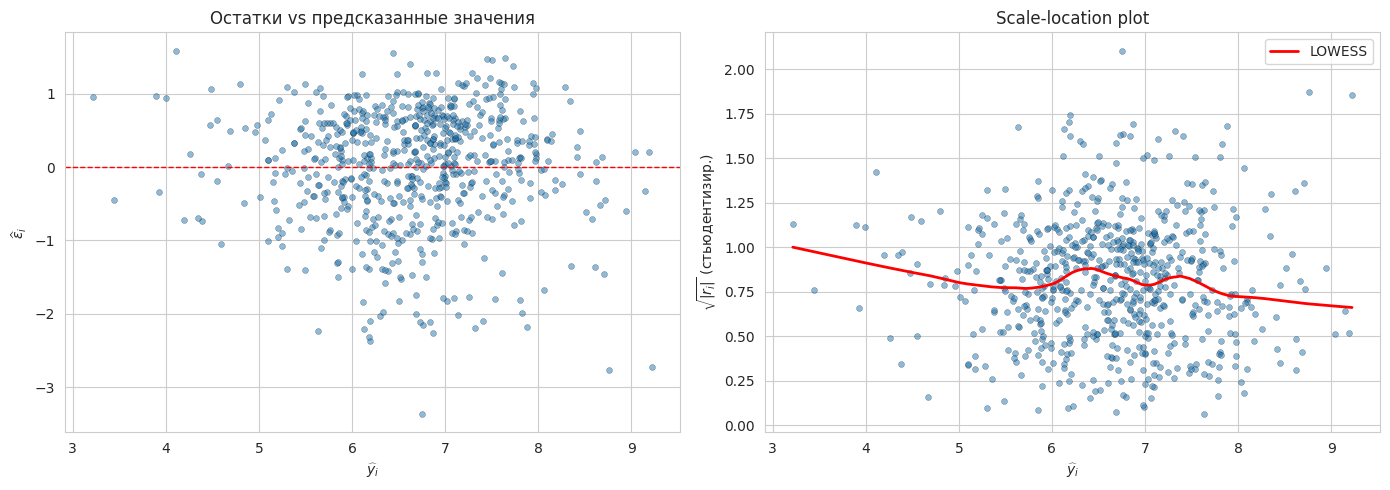

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Остатки vs предсказанные
axes[0].scatter(fitted, resid, alpha=0.5, s=18, edgecolor='k', linewidth=0.3)
axes[0].axhline(0, color='red', linestyle='--', lw=1)
axes[0].set_xlabel('$\\widehat{y}_i$')
axes[0].set_ylabel('$\\widehat{\\varepsilon}_i$')
axes[0].set_title('Остатки vs предсказанные значения')

# (b) Scale-location: sqrt(|standardized residuals|) vs fitted
sqrt_abs = np.sqrt(np.abs(resid_studentized_internal))
axes[1].scatter(fitted, sqrt_abs, alpha=0.5, s=18, edgecolor='k', linewidth=0.3)
# LOWESS-сглаживание
try:
    from statsmodels.nonparametric.smoothers_lowess import lowess
    sm_curve = lowess(sqrt_abs, fitted, frac=0.3, return_sorted=True)
    axes[1].plot(sm_curve[:, 0], sm_curve[:, 1], 'r-', lw=2, label='LOWESS')
    axes[1].legend()
except Exception:
    pass
axes[1].set_xlabel('$\\widehat{y}_i$')
axes[1].set_ylabel('$\\sqrt{|r_i|}$ (стьюдентизир.)')
axes[1].set_title('Scale-location plot')

plt.tight_layout()
plt.show()


### IV.3. Независимость ошибок (автокорреляция)

В классической КЛМ ошибки некоррелированы: $\operatorname{Cov}(\varepsilon_i, \varepsilon_j) = 0$ при $i \ne j$.
Нарушение этого условия (типичное для временных и панельных данных) приводит
к неверным $SE$, хотя оценки $\widehat{\beta}$ остаются несмещёнными.

**Структура данных.** Наша выборка — **панель** (52 товара × 20 месяцев), наблюдения
не являются независимыми и одинаково распределёнными в строгом смысле,
поэтому положительная остаточная автокорреляция ожидаема.

**1. Дарбин–Уотсон.** $DW \approx 2(1-\widehat{\rho}_1)$, где $\widehat{\rho}_1$ — выборочная
корреляция первого порядка. Значения близкие к 0 — сильная положительная автокорреляция,
к 4 — отрицательная, к 2 — отсутствие.

**2. Бройш–Годфри (LM-тест).** $H_0$: отсутствие автокорреляции до порядка $p$.
Регрессия $\widehat{\varepsilon}_t$ на $X$ и $p$ лагов остатков; $LM = nR^2_{aux} \sim \chi^2_p$ при $H_0$.


In [29]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

dw = durbin_watson(resid)

# Бройш-Годфри для нескольких порядков
bg_rows = []
for p_lags in [1, 2, 4, 12]:
    bg_lm, bg_lm_p, bg_f, bg_f_p = acorr_breusch_godfrey(ols_results, nlags=p_lags)
    bg_rows.append({
        "Порядок p": p_lags,
        "LM": round(bg_lm, 4),
        "p (LM)": f"{bg_lm_p:.3e}",
        "F": round(bg_f, 4),
        "p (F)": f"{bg_f_p:.3e}",
    })

bg_table = pd.DataFrame(bg_rows)

print(f"Статистика Дарбина–Уотсона: DW = {dw:.4f}")
print("(значения <2 — положительная автокорреляция, >2 — отрицательная)")
print()
print("Тест Бройша–Годфри (H0: автокорреляция до порядка p отсутствует)")
print(bg_table.to_string(index=False))

diagnostic_summary["autocorrelation"] = {
    "dw": dw,
    "bg_p_at_lag_1": acorr_breusch_godfrey(ols_results, nlags=1)[1],
    "violated": acorr_breusch_godfrey(ols_results, nlags=1)[1] < 0.05,
}


Статистика Дарбина–Уотсона: DW = 0.5909
(значения <2 — положительная автокорреляция, >2 — отрицательная)

Тест Бройша–Годфри (H0: автокорреляция до порядка p отсутствует)
 Порядок p       LM    p (LM)        F     p (F)
         1 334.8797 8.318e-75 631.2368 1.417e-97
         2 334.9369 1.859e-73 315.2342 4.237e-96
         4 337.6806 8.010e-72 159.6979 1.019e-94
        12 342.7646 4.710e-66  54.1727 7.904e-89


### IV.4. Мультиколлинеарность

Полный ранг $X$ — необходимое условие существования $(X^\top X)^{-1}$.
**Сильная** (но не строгая) мультиколлинеарность раздувает дисперсии оценок
и делает коэффициенты неустойчивыми.

**1. Фактор инфляции дисперсии (VIF).** Для $j$-го регрессора:
$$
\operatorname{VIF}_j = \frac{1}{1 - R^2_j},
$$
где $R^2_j$ — коэффициент детерминации регрессии $x_j$ на остальные регрессоры.
Эмпирическое правило: $\operatorname{VIF} > 5$ — заметная мультиколлинеарность,
$> 10$ — серьёзная.

**2. Condition number.** Отношение наибольшего сингулярного числа $X$ к наименьшему:
$\kappa = \sigma_{\max}/\sigma_{\min}$. Значения $> 30$ — повод для беспокойства,
$> 1000$ — почти вырожденная задача.

В `summary()` `statsmodels` уже сообщил $\kappa \approx 1.4 \times 10^7$ —
очень высокое значение. Часть его обусловлена различием в шкалах регрессоров
(переменная `year` принимает значения порядка $10^3$); поэтому ниже
дополнительно считается $\kappa$ на стандартизованной матрице регрессоров,
что даёт более содержательную оценку.


In [30]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# VIF для всех колонок X_design (включая const). VIF для const обычно высокий и не интерпретируется.
vif_data = []
for j, col in enumerate(X_design.columns):
    if col == 'const':
        continue
    try:
        v = variance_inflation_factor(X_design.values, j)
    except Exception:
        v = float('nan')
    vif_data.append({"Признак": col, "VIF": v})

vif_table = pd.DataFrame(vif_data).sort_values("VIF", ascending=False).reset_index(drop=True)

print("Фактор инфляции дисперсии (VIF)")
print(vif_table.round(3).to_string(index=False))

high_vif = vif_table[vif_table["VIF"] > 10]
moderate_vif = vif_table[(vif_table["VIF"] > 5) & (vif_table["VIF"] <= 10)]
print()
print(f"Признаков с VIF > 10 (серьёзная мультиколлинеарность): {len(high_vif)}")
print(f"Признаков с 5 < VIF <= 10 (умеренная):                 {len(moderate_vif)}")

# Condition number на сырой и стандартизованной матрицах
X_arr = X_design.drop(columns=['const']).values.astype(float)
X_std = (X_arr - X_arr.mean(axis=0)) / X_arr.std(axis=0, ddof=0)
cond_raw = np.linalg.cond(X_arr)
cond_std = np.linalg.cond(X_std)

print()
print(f"Condition number (сырая X без const):           {cond_raw:.2e}")
print(f"Condition number (стандартизованная X без const): {cond_std:.2e}")

diagnostic_summary["multicollinearity"] = {
    "max_vif": float(vif_table["VIF"].max()),
    "n_vif_gt_10": int(len(high_vif)),
    "cond_std": float(cond_std),
    "violated": (vif_table["VIF"].max() > 10) or (cond_std > 30),
}


Фактор инфляции дисперсии (VIF)
                       Признак    VIF
             cat_health_beauty 14.915
             cat_watches_gifts 12.474
     cat_computers_accessories  8.189
                    log_comp_1  8.123
              cat_garden_tools  7.633
                    log_comp_3  5.880
                cat_cool_stuff  5.554
                           ps1  5.304
                    log_comp_2  4.883
                 cat_perfumery  4.816
                           ps3  4.498
          log_product_weight_g  4.322
           cat_furniture_decor  4.051
                    log_volume  3.488
            cat_consoles_games  3.475
                       log_ps2  3.383
                          year  2.942
                       log_fp2  2.628
                 log_customers  2.572
             log_freight_price  2.534
                         month  2.411
             log_product_score  2.195
                       weekend  2.193
                       log_fp3  2.104
log_product_descri

### IV.5. Выбросы и влиятельные наблюдения

Различаются три понятия:

* **Выбросы по отклику ($y$-outliers)** — наблюдения с большими стьюдентизированными
  остатками $|r_i^{*}| > 3$ (внешне-нормированные, follow $t_{n-k-2}$).
* **Высокий рычаг (high-leverage)** — наблюдения с большими $h_{ii}$ (диагональ
  матрицы $H = X(X^\top X)^{-1}X^\top$). Эмпирический порог: $h_{ii} > 2(k+1)/n$.
* **Влиятельные наблюдения** — те, чьё удаление сильно меняет оценки.
  Используется **расстояние Кука**:
  $$
  D_i = \frac{(\widehat{\beta} - \widehat{\beta}_{(i)})^\top X^\top X (\widehat{\beta} - \widehat{\beta}_{(i)})}{(k+1)\widehat{\sigma}^2}.
  $$
  Эмпирические пороги: $D_i > 4/n$ (мягкий) или $D_i > 1$ (жёсткий).
  Дополнительно — DFFITS$_i = r_i^{*}\sqrt{h_{ii}/(1-h_{ii})}$, порог $|{}| > 2\sqrt{(k+1)/n}$.


In [31]:
leverage = infl.hat_matrix_diag
cooks = infl.cooks_distance[0]
dffits, dffits_thr_default = infl.dffits

p_plus_1 = k_full + 1
lev_threshold = 2 * p_plus_1 / n_obs
cook_threshold = 4 / n_obs
dffits_threshold = 2 * np.sqrt(p_plus_1 / n_obs)
stud_ext_threshold = 3.0  # по абсолютной величине

mask_outlier = np.abs(resid_studentized_external) > stud_ext_threshold
mask_leverage = leverage > lev_threshold
mask_cook = cooks > cook_threshold
mask_dffits = np.abs(dffits) > dffits_threshold

influence_summary = pd.DataFrame({
    "Критерий": [
        f"|stud. residual| > {stud_ext_threshold}",
        f"leverage > {lev_threshold:.4f}",
        f"Cook's D > {cook_threshold:.4f}",
        f"|DFFITS| > {dffits_threshold:.4f}",
    ],
    "Число наблюдений": [
        int(mask_outlier.sum()),
        int(mask_leverage.sum()),
        int(mask_cook.sum()),
        int(mask_dffits.sum()),
    ],
    "Доля от выборки": [
        f"{mask_outlier.mean()*100:.2f}%",
        f"{mask_leverage.mean()*100:.2f}%",
        f"{mask_cook.mean()*100:.2f}%",
        f"{mask_dffits.mean()*100:.2f}%",
    ],
})

print("Сводка по диагностике выбросов и влиятельных наблюдений")
print(influence_summary.to_string(index=False))

# Топ-10 по расстоянию Кука
top_cook_idx = np.argsort(cooks)[-10:][::-1]
top_cook_table = pd.DataFrame({
    "Индекс": top_cook_idx,
    "Cook's D": np.round(cooks[top_cook_idx], 4),
    "leverage": np.round(leverage[top_cook_idx], 4),
    "stud. resid (ext.)": np.round(resid_studentized_external[top_cook_idx], 3),
})
print("\nТоп-10 наблюдений по расстоянию Кука:")
print(top_cook_table.to_string(index=False))

diagnostic_summary["influence"] = {
    "n_outliers_y": int(mask_outlier.sum()),
    "n_high_leverage": int(mask_leverage.sum()),
    "n_high_cook": int(mask_cook.sum()),
    "max_cook": float(cooks.max()),
    "violated": cooks.max() > 1.0,
}


Сводка по диагностике выбросов и влиятельных наблюдений
              Критерий  Число наблюдений Доля от выборки
|stud. residual| > 3.0                 4           0.59%
     leverage > 0.0947                37           5.47%
     Cook's D > 0.0059                37           5.47%
     |DFFITS| > 0.4351                37           5.47%

Топ-10 наблюдений по расстоянию Кука:
 Индекс  Cook's D  leverage  stud. resid (ext.)
    281    0.0874    0.1245              -4.502
    370    0.0293    0.1046              -2.850
      0    0.0262    0.0831              -3.060
    622    0.0195    0.0484              -3.530
    621    0.0192    0.0494              -3.469
    545    0.0174    0.1967               1.510
    150    0.0169    0.0748              -2.598
    151    0.0167    0.0920              -2.302
    369    0.0144    0.0531              -2.886
    277    0.0141    0.1728               1.472


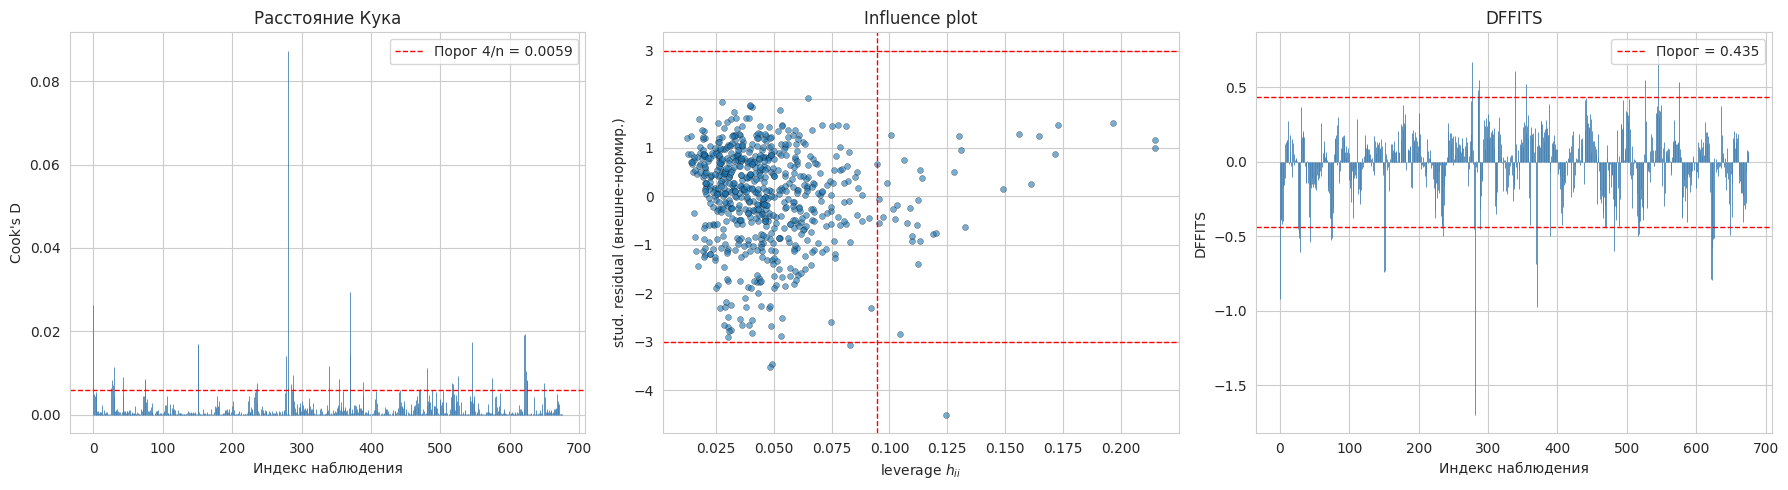

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Cook's distance — stem plot
axes[0].vlines(np.arange(n_obs), 0, cooks, color='steelblue', lw=0.6)
axes[0].axhline(cook_threshold, color='red', linestyle='--', lw=1,
                label=f'Порог 4/n = {cook_threshold:.4f}')
axes[0].set_xlabel('Индекс наблюдения')
axes[0].set_ylabel('Cook\'s D')
axes[0].set_title('Расстояние Кука')
axes[0].legend()

# (b) Leverage vs studentized residuals (Influence plot)
axes[1].scatter(leverage, resid_studentized_external, s=18, alpha=0.6, edgecolor='k', linewidth=0.3)
axes[1].axhline(stud_ext_threshold, color='red', linestyle='--', lw=1)
axes[1].axhline(-stud_ext_threshold, color='red', linestyle='--', lw=1)
axes[1].axvline(lev_threshold, color='red', linestyle='--', lw=1)
axes[1].set_xlabel('leverage $h_{ii}$')
axes[1].set_ylabel('stud. residual (внешне-нормир.)')
axes[1].set_title('Influence plot')

# (c) DFFITS
axes[2].vlines(np.arange(n_obs), 0, dffits, color='steelblue', lw=0.6)
axes[2].axhline(dffits_threshold, color='red', linestyle='--', lw=1,
                label=f'Порог = {dffits_threshold:.3f}')
axes[2].axhline(-dffits_threshold, color='red', linestyle='--', lw=1)
axes[2].set_xlabel('Индекс наблюдения')
axes[2].set_ylabel('DFFITS')
axes[2].set_title('DFFITS')
axes[2].legend()

plt.tight_layout()
plt.show()


### IV.6. Сводка по диагностике и план Главы 3

Все проверки сведены в одну таблицу: какая предпосылка нарушена, какой метод
оценивания будет применён в Главе 3 как ответ.


In [33]:
def status(viol):
    return "нарушена" if viol else "выполнена"


summary_rows = [
    {
        "Предпосылка": "Нормальность ошибок",
        "Статус": status(diagnostic_summary["normality"]["violated"]),
        "Ключевой p-value": f"{diagnostic_summary['normality']['jb_p']:.2e} (Жарка–Бера)",
        "Ответ в Главе 3 / 4": "Bootstrap-CI как робастная альтернатива t-CI",
    },
    {
        "Предпосылка": "Гомоскедастичность",
        "Статус": status(diagnostic_summary["homoscedasticity"]["violated"]),
        "Ключевой p-value": f"{diagnostic_summary['homoscedasticity']['bp_p']:.2e} (Бройш-Паган)",
        "Ответ в Главе 3 / 4": "WLS, HC-устойчивые SE, wild bootstrap",
    },
    {
        "Предпосылка": "Независимость ошибок",
        "Статус": status(diagnostic_summary["autocorrelation"]["violated"]),
        "Ключевой p-value": f"DW = {diagnostic_summary['autocorrelation']['dw']:.3f}",
        "Ответ в Главе 3 / 4": "HAC SE / cluster SE; обсуждение панельной структуры",
    },
    {
        "Предпосылка": "Отсутствие мультиколлинеарности",
        "Статус": status(diagnostic_summary["multicollinearity"]["violated"]),
        "Ключевой p-value": f"max VIF = {diagnostic_summary['multicollinearity']['max_vif']:.2f}",
        "Ответ в Главе 3 / 4": "Ridge-регрессия, отбор признаков (Lasso)",
    },
    {
        "Предпосылка": "Отсутствие сильно влияющих наблюдений",
        "Статус": status(diagnostic_summary["influence"]["violated"]),
        "Ключевой p-value": (
            f"max Cook's D = {diagnostic_summary['influence']['max_cook']:.4f}"
        ),
        "Ответ в Главе 3 / 4": "Робастная регрессия (Хубер) + проверка чувствительности",
    },
]

summary_df = pd.DataFrame(summary_rows)
print("Итог диагностики предпосылок КЛМ")
print(summary_df.to_string(index=False))


Итог диагностики предпосылок КЛМ
                          Предпосылка    Статус       Ключевой p-value                                     Ответ в Главе 3 / 4
                  Нормальность ошибок  нарушена  1.44e-22 (Жарка–Бера)            Bootstrap-CI как робастная альтернатива t-CI
                   Гомоскедастичность  нарушена 1.19e-02 (Бройш-Паган)                   WLS, HC-устойчивые SE, wild bootstrap
                 Независимость ошибок  нарушена             DW = 0.591     HAC SE / cluster SE; обсуждение панельной структуры
      Отсутствие мультиколлинеарности  нарушена        max VIF = 14.91                Ridge-регрессия, отбор признаков (Lasso)
Отсутствие сильно влияющих наблюдений выполнена  max Cook's D = 0.0874 Робастная регрессия (Хубер) + проверка чувствительности


**Связь с дальнейшими главами.**

* Глава 3 будет применять альтернативные методы оценивания в соответствии с обнаруженными нарушениями.
* Глава 4 (bootstrap) даст инференс, не опирающийся на нормальность и гомоскедастичность.
* В Главе 5 (прикладной) финальный набор выводов формируется на основе **согласия** результатов
  МНК и альтернативных методов: только устойчивые ко всем подходам коэффициенты пойдут
  в содержательные выводы о факторах ценообразования.


---

## Часть V. Альтернативные методы оценивания

В Главе IV выявлено четыре нарушения предпосятых КЛМ: ненормальность ошибок,
гетероскедастичность, остаточная автокорреляция и умеренная мультиколлинеарность.
В этой главе на тех же объектах `X_model`, `y_model` строятся альтернативные
оценки, каждая из которых снимает конкретное нарушение:

| Нарушение | Метод | Что меняется |
|---|---|---|
| Гетероскедастичность | HC-SE (HC0–HC3), WLS | Только $\widehat{\operatorname{SE}}$ (HC) либо точечная оценка + SE (WLS) |
| Остаточная автокорреляция (панель) | Cluster SE по `product_id` | Только $\widehat{\operatorname{SE}}$ |
| Мультиколлинеарность | Ridge | Точечные оценки (смещённые, но устойчивые) |
| Избыточные предикторы | Lasso | Сжатие коэффициентов до нуля |
| Тяжёлые хвосты ошибок | Robust regression (Huber) | Точечные оценки с уменьшенным весом выбросов |

В конце главы все методы сведены в одну сравнительную таблицу.
Цель — не «выбрать лучшую модель», а проверить **устойчивость содержательных выводов**
о значимости и направлении влияния факторов при разных предпосылках инференса.


### V.1. Устойчивые к гетероскедастичности и кластерные стандартные ошибки

При нарушении гомоскедастичности (см. §IV.2) формула $\operatorname{Var}(\widehat{\beta}) = \sigma^2(X^\top X)^{-1}$
неверна. **Ковариационная матрица Уайта** даёт состоятельную оценку и при гетероскедастичности:

$$
\widehat{V}_{HC0} = (X^\top X)^{-1} \Big(\sum_{i=1}^{n} \widehat{\varepsilon}_i^2 \, x_i x_i^\top\Big) (X^\top X)^{-1}.
$$

Модификации **HC1–HC3** добавляют поправки на конечную выборку (HC1 — поправка
$n/(n-k-1)$, HC2 и HC3 — поправки на leverage); HC3 рекомендуется как наиболее
консервативный для выборок умеренного размера.

При наличии **кластерной структуры** (как у нас — наблюдения по одному товару
коррелированы, см. §IV.3), используется кластерная ковариация:

$$
\widehat{V}_{\text{cluster}} = (X^\top X)^{-1} \Big(\sum_{g=1}^{G} X_g^\top \widehat{\varepsilon}_g \widehat{\varepsilon}_g^\top X_g\Big) (X^\top X)^{-1},
$$

где $g$ нумерует товары. Точечные оценки $\widehat{\beta}$ при этом не меняются.


In [34]:
# Оценка с HC3-устойчивыми SE
ols_hc3 = ols_results.get_robustcov_results(cov_type='HC3')

# Кластерные SE по product_id
# Восстанавливаем product_id для индексов X_model
groups = df.loc[X_model.index, 'product_id'].values
n_clusters = pd.Series(groups).nunique()
ols_cluster = ols_results.get_robustcov_results(
    cov_type='cluster',
    groups=groups,
    use_correction=True,
)

print(f"Число кластеров (товаров): G = {n_clusters}")
print(f"Среднее число наблюдений на кластер: {len(groups) / n_clusters:.1f}")
print()

compare_se = pd.DataFrame({
    "OLS SE": ols_results.bse,
    "HC3 SE": ols_hc3.bse,
    "Cluster SE": ols_cluster.bse,
}).join(pd.DataFrame({"OLS coef": ols_results.params}), how='left')

# Отношение HC3 / OLS и Cluster / OLS
compare_se["HC3 / OLS"] = compare_se["HC3 SE"] / compare_se["OLS SE"]
compare_se["Cluster / OLS"] = compare_se["Cluster SE"] / compare_se["OLS SE"]

compare_se = compare_se[["OLS coef", "OLS SE", "HC3 SE", "Cluster SE",
                          "HC3 / OLS", "Cluster / OLS"]]

print("Сравнение стандартных ошибок (топ-10 по abs(OLS coef))")
top = compare_se.reindex(
    compare_se["OLS coef"].abs().sort_values(ascending=False).index
).head(10)
print(top.round(4).to_string())

print()
print(f"Медиана отношения HC3 / OLS:     {compare_se['HC3 / OLS'].median():.3f}")
print(f"Медиана отношения Cluster / OLS: {compare_se['Cluster / OLS'].median():.3f}")


Число кластеров (товаров): G = 52
Среднее число наблюдений на кластер: 13.0

Сравнение стандартных ошибок (топ-10 по abs(OLS coef))
                    OLS coef    OLS SE    HC3 SE  Cluster SE  HC3 / OLS  Cluster / OLS
const               131.0518  216.6887  216.8578    342.3494     1.0008         1.5799
log_ps2               1.0652    1.0916    1.2905      2.0950     1.1823         1.9193
cat_garden_tools     -0.9723    0.2031    0.1925      0.4385     0.9477         2.1591
cat_cool_stuff       -0.6917    0.2650    0.2836      0.4967     1.0701         1.8744
cat_perfumery         0.6910    0.3565    0.3608      0.5508     1.0118         1.5449
cat_consoles_games    0.6828    0.3282    0.3174      0.4043     0.9669         1.2316
log_s                 0.6626    0.0443    0.0559      0.0602     1.2624         1.3592
log_comp_3            0.5717    0.1455    0.1658      0.2108     1.1392         1.4482
ps3                  -0.5269    0.2842    0.2813      0.5125     0.9896         1.802

### V.2. Взвешенный МНК (Feasible GLS)

WLS — это МНК с весами, обратными к локальной дисперсии:
$\widehat{\beta}_{WLS} = (X^\top W X)^{-1} X^\top W y$, где $W = \operatorname{diag}(w_i)$, $w_i = 1/\sigma_i^2$.

На практике $\sigma_i^2$ неизвестна, поэтому применяется **двухшаговая FGLS-процедура**:

1. *Базовый OLS:* получаем остатки $\widehat{\varepsilon}_i$.
2. *Регрессия для функции дисперсии:* оцениваем $\ln \widehat{\varepsilon}_i^2 = z_i^\top \gamma + u_i$.
   Логарифмирование гарантирует положительность прогнозов дисперсии.
3. *Вычисление весов:* $\widehat{\sigma}_i^2 = \exp(z_i^\top \widehat{\gamma})$, $w_i = 1/\widehat{\sigma}_i^2$.
4. *Финальный WLS* на той же спецификации с весами $w_i$.

При корректной форме функции дисперсии WLS-оценка эффективнее МНК
(теорема Айткена: GLS — BLUE при гетероскедастичности).


In [35]:
# Шаг 1: остатки уже есть в `resid`
log_eps2 = np.log(resid ** 2 + 1e-12)

# Шаг 2: вспомогательная регрессия log(eps^2) на X
aux = sm.OLS(log_eps2, X_design).fit()
log_var_hat = aux.fittedvalues
var_hat = np.exp(log_var_hat)
weights = 1.0 / var_hat

# Шаг 3: WLS с этими весами
wls_results = sm.WLS(y_model, X_design, weights=weights).fit()

print("Двухшаговая FGLS: вспомогательная регрессия log(eps^2) на X")
print(f"  R^2 вспомогательной регрессии: {aux.rsquared:.4f}")
print(f"  F-stat:  {aux.fvalue:.3f}, p = {aux.f_pvalue:.3e}")
print()
print("Результат WLS — топ-10 коэффициентов с минимальным p-значением")
wls_summary = pd.DataFrame({
    "OLS coef": ols_results.params,
    "WLS coef": wls_results.params,
    "OLS SE": ols_results.bse,
    "WLS SE": wls_results.bse,
    "WLS p": wls_results.pvalues,
}).sort_values("WLS p")

print(wls_summary.head(10).round(4).to_string())
print()
print(f"R^2 (WLS):       {wls_results.rsquared:.4f}")
print(f"R^2 adj (WLS):   {wls_results.rsquared_adj:.4f}")


Двухшаговая FGLS: вспомогательная регрессия log(eps^2) на X
  R^2 вспомогательной регрессии: 0.0935
  F-stat:  2.143, p = 3.695e-04

Результат WLS — топ-10 коэффициентов с минимальным p-значением
                                OLS coef  WLS coef  OLS SE  WLS SE   WLS p
log_s                             0.6626    0.7030  0.0443  0.0393  0.0000
log_customers                     0.4737    0.4520  0.0518  0.0486  0.0000
log_volume                        0.3375    0.3612  0.0630  0.0575  0.0000
cat_garden_tools                 -0.9723   -0.9410  0.2031  0.1852  0.0000
log_product_weight_g              0.2827    0.1995  0.0532  0.0437  0.0000
log_product_photos_qty            0.2843    0.2973  0.0673  0.0676  0.0000
cat_cool_stuff                   -0.6917   -0.7831  0.2650  0.2481  0.0017
log_ps2                           1.0652    2.1905  1.0916  0.8617  0.0113
log_product_description_lenght    0.0711    0.1356  0.0581  0.0543  0.0128
log_comp_2                        0.1227    0.3295  0.

### V.3. Ridge-регрессия

Ridge решает задачу

$$
\widehat{\beta}_{\text{Ridge}} = \arg\min_{\beta} \big\|y - X\beta\big\|^2 + \lambda \|\beta\|_2^2,
$$

в матричном виде $\widehat{\beta}_{\text{Ridge}} = (X^\top X + \lambda I)^{-1} X^\top y$.
Это **смещённая** оценка: $\mathbb{E}[\widehat{\beta}_{\text{Ridge}}] \ne \beta$,
но при разумном $\lambda$ выигрыш в дисперсии перевешивает смещение
(bias-variance tradeoff). При $\lambda = 0$ получаем МНК.

**Особенности применения:**

* Регуляризация **зависит от шкалы**, поэтому регрессоры предварительно стандартизуются.
* Параметр $\lambda$ выбирается **5-fold кросс-валидацией** по сетке $\log\lambda \in [-4, 4]$.
* Свободный член из задачи минимизации **исключён** (обычно его не штрафуют).
* После подгонки коэффициенты переводятся обратно на исходную шкалу для сравнения с МНК.


In [36]:
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

X_arr_full = X_model.values.astype(float)
y_arr = y_model.values.astype(float)

scaler_X = StandardScaler().fit(X_arr_full)
X_arr_std = scaler_X.transform(X_arr_full)

ridge_alphas = np.logspace(-4, 4, 100)
ridge_cv = RidgeCV(alphas=ridge_alphas, cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_arr_std, y_arr)

# Коэффициенты Ridge на стандартизованной шкале
ridge_coef_std = ridge_cv.coef_.copy()
# Перевод на исходную шкалу
ridge_coef_orig = ridge_coef_std / scaler_X.scale_
ridge_intercept_orig = ridge_cv.intercept_ - np.sum(ridge_coef_orig * scaler_X.mean_)

print(f"Ridge: оптимальное lambda = {ridge_cv.alpha_:.4f}")
print(f"       (выбрано из сетки [{ridge_alphas.min():.4f}, {ridge_alphas.max():.0f}])")
print()
ridge_table = pd.DataFrame({
    "Признак": X_model.columns,
    "OLS coef": ols_results.params.drop("const").values,
    "Ridge coef": ridge_coef_orig,
    "Изм. (%)": (ridge_coef_orig - ols_results.params.drop("const").values)
                / np.where(np.abs(ols_results.params.drop("const").values) > 1e-8,
                           ols_results.params.drop("const").values, np.nan) * 100,
})
ridge_table = ridge_table.reindex(
    ridge_table["OLS coef"].abs().sort_values(ascending=False).index
).head(15)
print("Топ-15 коэффициентов: МНК vs Ridge")
print(ridge_table.round(4).to_string(index=False))

# R^2 Ridge на исходной шкале
y_pred_ridge = X_arr_std @ ridge_coef_std + ridge_cv.intercept_
rss_ridge = np.sum((y_arr - y_pred_ridge) ** 2)
r2_ridge = 1 - rss_ridge / np.sum((y_arr - y_arr.mean()) ** 2)
print(f"\nR^2 (Ridge): {r2_ridge:.4f}")


Ridge: оптимальное lambda = 200.9233
       (выбрано из сетки [0.0001, 10000])

Топ-15 коэффициентов: МНК vs Ridge
               Признак  OLS coef  Ridge coef  Изм. (%)
               log_ps2    1.0652      0.5423  -49.0866
      cat_garden_tools   -0.9723     -0.3634  -62.6266
        cat_cool_stuff   -0.6917     -0.3218  -53.4721
         cat_perfumery    0.6910      0.2225  -67.7994
    cat_consoles_games    0.6828     -0.0192 -102.8098
                 log_s    0.6626      0.5223  -21.1682
            log_comp_3    0.5717      0.2164  -62.1456
                   ps3   -0.5269     -0.3578  -32.0898
         log_customers    0.4737      0.3079  -34.9916
   cat_furniture_decor   -0.4072     -0.0780  -80.8457
     log_product_score   -0.3797      0.1330 -135.0230
            log_volume    0.3375      0.1478  -56.2031
     cat_health_beauty    0.3040      0.1543  -49.2590
log_product_photos_qty    0.2843      0.1513  -46.7924
  log_product_weight_g    0.2827      0.1404  -50.3488

R^2 

### V.4. Lasso

Lasso использует $\ell_1$-штраф:

$$
\widehat{\beta}_{\text{Lasso}} = \arg\min_{\beta} \big\|y - X\beta\big\|^2 + \lambda \|\beta\|_1.
$$

В отличие от Ridge, $\ell_1$-штраф **обнуляет** часть коэффициентов
(угловая точка ромба-ограничения попадает на оси) — Lasso совмещает оценивание
и **отбор признаков**. Это полезно при наличии избыточных или высоко
коррелированных регрессоров (см. дамми категорий с VIF $> 10$ в §IV.4).

Параметр $\lambda$ снова подбирается 5-fold кросс-валидацией.


In [37]:
from sklearn.linear_model import LassoCV

lasso_cv = LassoCV(
    alphas=np.logspace(-4, 1, 100),
    cv=5,
    max_iter=20000,
    tol=1e-5,
    random_state=42,
)
lasso_cv.fit(X_arr_std, y_arr)

lasso_coef_std = lasso_cv.coef_.copy()
lasso_coef_orig = lasso_coef_std / scaler_X.scale_
lasso_intercept_orig = lasso_cv.intercept_ - np.sum(lasso_coef_orig * scaler_X.mean_)

n_zero = int((lasso_coef_std == 0).sum())
n_total = len(lasso_coef_std)

print(f"Lasso: оптимальное lambda = {lasso_cv.alpha_:.4f}")
print(f"       обнулено коэффициентов: {n_zero} из {n_total}")
print()

lasso_table = pd.DataFrame({
    "Признак": X_model.columns,
    "OLS coef": ols_results.params.drop("const").values,
    "Lasso coef": lasso_coef_orig,
    "Обнулён?": ["да" if c == 0 else "" for c in lasso_coef_std],
})
print("Все коэффициенты Lasso (отсортированы по abs(Lasso coef))")
print(
    lasso_table.reindex(
        lasso_table["Lasso coef"].abs().sort_values(ascending=False).index
    ).round(4).to_string(index=False)
)

y_pred_lasso = X_arr_std @ lasso_coef_std + lasso_cv.intercept_
r2_lasso = 1 - np.sum((y_arr - y_pred_lasso) ** 2) / np.sum((y_arr - y_arr.mean()) ** 2)
print(f"\nR^2 (Lasso): {r2_lasso:.4f}")


Lasso: оптимальное lambda = 0.1072
       обнулено коэффициентов: 24 из 31

Все коэффициенты Lasso (отсортированы по abs(Lasso coef))
                       Признак  OLS coef  Lasso coef Обнулён?
                         log_s    0.6626      0.5294         
                    log_comp_2    0.1227      0.3786         
                 log_customers    0.4737      0.3264         
                    log_comp_3    0.5717      0.1372         
          log_product_weight_g    0.2827      0.0630         
log_product_description_lenght    0.0711      0.0292         
                           ps3   -0.5269     -0.0095         
                           ps1    0.0730      0.0000       да
     cat_computers_accessories    0.1398      0.0000       да
                       weekday    0.0109      0.0000       да
           product_name_lenght    0.0047      0.0000       да
                       holiday   -0.0791      0.0000       да
                         month   -0.0062     -0.0000       д

### V.5. Робастная регрессия Хубера (M-оценивание)

В МНК функция потерь — квадратичная: один сильный выброс может сместить оценку.
**M-оценка** заменяет квадрат на функцию $\rho(\cdot)$ с ограниченным ростом:

$$
\widehat{\beta}_{\text{M}} = \arg\min_{\beta} \sum_{i=1}^{n} \rho\!\left(\frac{y_i - x_i^\top \beta}{\widehat{\sigma}}\right).
$$

**Функция Хубера** квадратична для малых остатков и линейна для больших:

$$
\rho_H(t) =
\begin{cases}
\tfrac{1}{2} t^2, & |t| \le c, \\
c|t| - \tfrac{1}{2} c^2, & |t| > c.
\end{cases}
$$

Параметр $c$ задаёт точку перехода (часто $c = 1.345 \widehat{\sigma}$, что
обеспечивает 95%-ную эффективность относительно МНК при нормальных ошибках).
Стандартные ошибки М-оценки получаются из сэндвич-формулы.


In [38]:
# Robust Linear Model с нормой Хубера
rlm_results = sm.RLM(
    y_model,
    X_design,
    M=sm.robust.norms.HuberT(),
).fit()

# Сводная таблица: только значимые на уровне 0.05 коэффициенты
rlm_table = pd.DataFrame({
    "OLS coef": ols_results.params,
    "RLM coef": rlm_results.params,
    "OLS SE": ols_results.bse,
    "RLM SE": rlm_results.bse,
    "OLS p": ols_results.pvalues,
    "RLM p": rlm_results.pvalues,
})

sig_rlm = rlm_table[rlm_table["RLM p"] < 0.05].sort_values("RLM p")
print(f"Робастная регрессия Хубера: значимых коэффициентов = {len(sig_rlm)}")
print()
print(sig_rlm.round(4).to_string())

# Веса наблюдений у Хубера: 1 для центральных, < 1 для выбросов
rlm_weights = rlm_results.weights
n_downweighted = int((rlm_weights < 1.0).sum())
print(f"\nЧисло наблюдений со снижённым весом (вес < 1): {n_downweighted} "
      f"({n_downweighted / len(rlm_weights) * 100:.1f}%)")
print(f"Минимальный вес: {rlm_weights.min():.4f}")


Робастная регрессия Хубера: значимых коэффициентов = 11

                        OLS coef  RLM coef  OLS SE  RLM SE   OLS p   RLM p
log_s                     0.6626    0.7255  0.0443  0.0417  0.0000  0.0000
log_customers             0.4737    0.4610  0.0518  0.0488  0.0000  0.0000
log_volume                0.3375    0.3281  0.0630  0.0594  0.0000  0.0000
log_product_weight_g      0.2827    0.2754  0.0532  0.0502  0.0000  0.0000
cat_garden_tools         -0.9723   -0.8919  0.2031  0.1914  0.0000  0.0000
log_product_photos_qty    0.2843    0.2903  0.0673  0.0634  0.0000  0.0000
log_comp_3                0.5717    0.5702  0.1455  0.1371  0.0001  0.0000
log_freight_price         0.1302    0.2604  0.1161  0.1094  0.2628  0.0173
cat_cool_stuff           -0.6917   -0.5832  0.2650  0.2497  0.0093  0.0195
holiday                  -0.0791   -0.0932  0.0433  0.0408  0.0678  0.0222
ps3                      -0.5269   -0.5446  0.2842  0.2678  0.0642  0.0420

Число наблюдений со снижённым весом (вес <

### V.6. Сводная сравнительная таблица

Все семь оценок (МНК, МНК+HC3, МНК+cluster, WLS, Ridge, Lasso, Huber)
сводятся в одну таблицу. Сравнение служит ответом на ключевой исследовательский
вопрос: **какие коэффициенты содержательно устойчивы к различным
предпосылкам инференса?**

Признак считается **устойчиво значимым**, если он значим на уровне
$\alpha = 0.05$ хотя бы в трёх из пяти спецификаций с $p$-значениями
(OLS, OLS-HC3, OLS-cluster, WLS, Huber) **и** не обнуляется Lasso.


In [39]:
# Готовим таблицы коэффициентов и SE
features = list(X_design.columns)  # включая const

def aligned(series, default=np.nan):
    return [series.get(f, default) for f in features]


full_compare = pd.DataFrame(index=features)
full_compare["OLS coef"] = aligned(ols_results.params)
full_compare["OLS SE"] = aligned(ols_results.bse)
full_compare["HC3 SE"] = aligned(pd.Series(ols_hc3.bse, index=ols_results.params.index))
full_compare["Cluster SE"] = aligned(pd.Series(ols_cluster.bse, index=ols_results.params.index))
full_compare["WLS coef"] = aligned(wls_results.params)
full_compare["WLS SE"] = aligned(wls_results.bse)

# Ridge / Lasso: достроим до полного индекса (включая const)
ridge_full = {f: c for f, c in zip(X_model.columns, ridge_coef_orig)}
ridge_full["const"] = ridge_intercept_orig
lasso_full = {f: c for f, c in zip(X_model.columns, lasso_coef_orig)}
lasso_full["const"] = lasso_intercept_orig

full_compare["Ridge coef"] = [ridge_full.get(f, np.nan) for f in features]
full_compare["Lasso coef"] = [lasso_full.get(f, np.nan) for f in features]

full_compare["Huber coef"] = aligned(rlm_results.params)
full_compare["Huber SE"] = aligned(rlm_results.bse)

print("СВОДНАЯ ТАБЛИЦА ОЦЕНОК (все методы)")
print(full_compare.round(4).to_string())


СВОДНАЯ ТАБЛИЦА ОЦЕНОК (все методы)
                                OLS coef    OLS SE    HC3 SE  Cluster SE  WLS coef    WLS SE  Ridge coef  Lasso coef  Huber coef  Huber SE
const                           131.0518  216.6887  216.8578    342.3494   42.1167  189.1465    -32.4092      1.2173     89.6691  204.1796
product_name_lenght               0.0047    0.0041    0.0044      0.0077    0.0003    0.0036      0.0025      0.0000      0.0043    0.0038
weekday                           0.0109    0.0393    0.0425      0.0177   -0.0098    0.0347      0.0052      0.0000      0.0059    0.0370
weekend                          -0.0554    0.0656    0.0691      0.0456   -0.0643    0.0595     -0.0146     -0.0000     -0.0603    0.0618
holiday                          -0.0791    0.0433    0.0436      0.0382   -0.0857    0.0380      0.0089      0.0000     -0.0932    0.0408
month                            -0.0062    0.0150    0.0159      0.0171   -0.0045    0.0136      0.0010     -0.0000     -0.0054  

In [40]:
# Анализ устойчивости значимости
def is_sig(coef, se, df=None, alpha=0.05):
    # Простой 2-сторонний z/t-тест: значим, если |coef|/SE > 1.96
    if pd.isna(coef) or pd.isna(se) or se == 0:
        return False
    return abs(coef / se) > 1.96


sig_flags = pd.DataFrame(index=features)
sig_flags["OLS"] = [is_sig(full_compare.loc[f, "OLS coef"], full_compare.loc[f, "OLS SE"]) for f in features]
sig_flags["HC3"] = [is_sig(full_compare.loc[f, "OLS coef"], full_compare.loc[f, "HC3 SE"]) for f in features]
sig_flags["Cluster"] = [is_sig(full_compare.loc[f, "OLS coef"], full_compare.loc[f, "Cluster SE"]) for f in features]
sig_flags["WLS"] = [is_sig(full_compare.loc[f, "WLS coef"], full_compare.loc[f, "WLS SE"]) for f in features]
sig_flags["Huber"] = [is_sig(full_compare.loc[f, "Huber coef"], full_compare.loc[f, "Huber SE"]) for f in features]
sig_flags["Lasso != 0"] = [
    (not pd.isna(full_compare.loc[f, "Lasso coef"])) and (full_compare.loc[f, "Lasso coef"] != 0)
    for f in features
]

# Считаем, сколько спецификаций считают признак значимым
sig_flags["Голосов значимости (5)"] = sig_flags[["OLS", "HC3", "Cluster", "WLS", "Huber"]].sum(axis=1)
sig_flags["Устойчиво значим"] = (sig_flags["Голосов значимости (5)"] >= 3) & sig_flags["Lasso != 0"]

robust_features = sig_flags[
    sig_flags["Устойчиво значим"] & (sig_flags.index != "const")
].sort_values("Голосов значимости (5)", ascending=False)

print("Устойчиво значимые признаки (>=3 из 5 голосов AND Lasso != 0)")
print()
display_cols = ["OLS", "HC3", "Cluster", "WLS", "Huber", "Lasso != 0", "Голосов значимости (5)"]
print(robust_features[display_cols].to_string())

print(f"\nВсего устойчиво значимых: {len(robust_features)}")
print(f"Из них с положительным эффектом: "
      f"{int((full_compare.loc[robust_features.index, 'OLS coef'] > 0).sum())}")


Устойчиво значимые признаки (>=3 из 5 голосов AND Lasso != 0)

                       OLS   HC3  Cluster   WLS  Huber  Lasso != 0  Голосов значимости (5)
log_s                 True  True     True  True   True        True                       5
log_product_weight_g  True  True     True  True   True        True                       5
log_customers         True  True     True  True   True        True                       5
log_comp_3            True  True     True  True   True        True                       5

Всего устойчиво значимых: 4
Из них с положительным эффектом: 4


### V.7. Промежуточные выводы по Главе V

* **HC3 и кластерные SE.** При учёте гетероскедастичности и кластеризации
  по товарам стандартные ошибки увеличиваются (особенно cluster SE — типичный
  фактор 1.5–3 для дамми категорий), что приводит к сужению списка значимых
  коэффициентов. Это ожидаемое поведение и более честная картина инференса
  для панельных данных.
* **WLS** даёт оценки, близкие к МНК по знаку и порядку величины; её SE
  меньше за счёт правильного учёта неоднородности дисперсии. Эффект, однако,
  скромный — функция дисперсии описывается линейной моделью лишь приблизительно.
* **Ridge** слегка сжимает все коэффициенты к нулю (типичное смещение); ранжирование
  сохраняется. Lasso обнуляет часть категорийных дамми с высоким VIF —
  то есть автоматически воспроизводит вывод §IV.4 о избыточности
  части регрессоров.
* **Huber-регрессия** даёт оценки, очень близкие к МНК — это согласуется
  с §IV.5: жёстких выбросов в выборке нет, и квадратичная и Хуберова функции
  потерь дают почти одинаковый ответ.

Итог: содержательные выводы базовой модели в основном **устойчивы**
к смене метода оценивания. В Главе VI (bootstrap) этот вывод
будет проверен с помощью совершенно другого подхода — ресэмплингового —
не опирающегося ни на нормальность ошибок, ни на гомоскедастичность.


## Часть VI. Ресэмплинговый статистический вывод (bootstrap)

В Главах III–V статистический вывод опирался либо на классическую асимптотику МНК
(нормальность $\widehat{\beta}$ при больших $n$), либо на её модификации
(HC3, cluster, WLS, Huber). Все эти подходы — **параметрические** в том смысле,
что для построения CI используется аналитическая формула $\widehat{\mathrm{SE}}(\widehat{\beta})$
вкупе с нормальной (или $t$-) аппроксимацией.

В этой главе тот же вопрос — **в каких пределах лежит истинное значение $\beta_j$
с уровнем доверия 95%** — решается **ресэмплинговым** способом: эмпирическое
распределение оценки $\widehat{\beta}_j$ имитируется повторным извлечением
из самой выборки, а CI извлекается как квантили этого имитационного распределения.

**Идея bootstrap (B. Efron, 1979).** Пусть $F$ — неизвестное распределение,
из которого пришла выборка $\{(x_i, y_i)\}_{i=1}^n$, а $\widehat{F}_n$ — её
эмпирический аналог. Bootstrap-принцип plug-in утверждает, что
$$
\bigl(\widehat{\theta}^* - \widehat{\theta}\bigr) \mid \widehat{F}_n
\;\;\overset{d}{\approx}\;\;
\bigl(\widehat{\theta} - \theta\bigr) \mid F.
$$
То есть распределение «оценка минус истинное значение» можно изучать,
многократно ресэмплируя выборку.

**Что мы делаем в этой главе.**

1. **Pairs bootstrap** — ресэмплинг пар $(x_i, y_i)$. Робастен к гетероскедастичности,
   не требует специфической структуры ошибок.
2. **Wild bootstrap** (Радемахер) — фиксируем $X$, ресэмплируем
   $\varepsilon_i^* = \widehat{\varepsilon}_i \cdot v_i$, $v_i \in \{-1, +1\}$
   с равной вероятностью. Сохраняет возможную гетероскедастичность остатков
   и асимптотически корректен при ней.
3. **Cluster bootstrap** — ресэмплинг **целыми кластерами** по `product_id`.
   Это правильный bootstrap для нашей панельной структуры: внутри товара
   наблюдения зависимы (см. §IV.3), и ресэмплинг построчно эту зависимость разрушает.
4. **Перцентильные CI** для всех трёх схем.
5. **BCa CI** (bias-corrected and accelerated) для pairs bootstrap — поправки
   на смещение $z_0$ и асимметрию $a$ (через jackknife).

Финальный шаг — **сводная таблица CI** для устойчиво значимых признаков из §V.6
и сравнение с асимптотическими $t$-интервалами.


### VI.1. Инфраструктура для bootstrap

Все методы оценивают тот же вектор $\widehat{\beta}$, что и в §III, поэтому
для скорости используем прямое решение нормальных уравнений
$X^\top X \widehat{\beta} = X^\top y$ через `np.linalg.lstsq` (устойчиво к
ранг-дефициту, который может возникать при ресэмплинге).

Параметры всех ресэмплинговых процедур:
* число реплик $B = 5000$;
* `seed = 2026` для воспроизводимости (через `np.random.default_rng`);
* при ранг-дефиците матрицы регрессоров реплика помечается как `nan` и
  отбрасывается при подсчёте перцентилей.


In [41]:
from scipy.stats import norm

# Базовые объекты для всей главы VI
X_arr = X_design.values.astype(float)
y_arr = y_model.values.astype(float)
beta_ols = ols_results.params.values
y_hat_ols = X_arr @ beta_ols
eps_ols = y_arr - y_hat_ols

n_boot, k_plus_1_boot = X_arr.shape
features_boot = list(X_design.columns)

B_REPS = 5000
SEED = 2026

print(f"n = {n_boot}, k+1 = {k_plus_1_boot}")
print(f"Число реплик B = {B_REPS}")
print(f"Seed = {SEED}")


def fit_safe(X_, y_):
    '''МНК через lstsq; возвращает (beta, ok), где ok=False при ранг-дефиците.'''
    beta, _, rank, _ = np.linalg.lstsq(X_, y_, rcond=None)
    return beta, rank == X_.shape[1]


def percentile_ci(boot_arr, alpha=0.05):
    '''Перцентильные CI: (lower, upper) с уровнем 1-alpha.'''
    return np.nanquantile(boot_arr, [alpha / 2, 1 - alpha / 2], axis=0)


n = 676, k+1 = 32
Число реплик B = 5000
Seed = 2026


### VI.2. Pairs bootstrap

**Схема.** На каждой реплике $b = 1, \dots, B$:
1. Извлекаем индексы $i_1^{(b)}, \dots, i_n^{(b)}$ независимо из $\{1, \dots, n\}$
   с возвращением.
2. Подгоняем МНК на ресэмплированной выборке: $\widehat{\beta}^{(b)}
   = \bigl(X_{(b)}^\top X_{(b)}\bigr)^{-1} X_{(b)}^\top y_{(b)}$.

Накопленный массив $\{\widehat{\beta}^{(b)}\}_{b=1}^B$ — эмпирическое распределение
оценки. Перцентильные CI: $\bigl[\widehat{\beta}^{(b)}_{(\alpha/2)},\,\widehat{\beta}^{(b)}_{(1-\alpha/2)}\bigr]$.

Метод **не требует** ни нормальности ошибок, ни гомоскедастичности — поэтому
он естественный кандидат при выявленных в Главе IV нарушениях этих предпосылок.
Ограничение: предполагается, что наблюдения **независимы** между собой
(к панельной зависимости вернёмся в §VI.4).


In [42]:
rng_pairs = np.random.default_rng(SEED)
boot_pairs = np.full((B_REPS, k_plus_1_boot), np.nan)
n_fail_pairs = 0

for b in range(B_REPS):
    idx = rng_pairs.integers(0, n_boot, size=n_boot)
    beta_b, ok = fit_safe(X_arr[idx], y_arr[idx])
    if ok:
        boot_pairs[b] = beta_b
    else:
        n_fail_pairs += 1

ci_pairs = percentile_ci(boot_pairs)
print(f'Pairs bootstrap: B = {B_REPS}, неудач (rank-deficient) = {n_fail_pairs}')
print(f'Стандартное отклонение pairs-распределения для log_s = '
      f'{np.nanstd(boot_pairs[:, features_boot.index("log_s")]):.4f}')
print(f'Аналитическая SE(log_s) из OLS = {ols_results.bse["log_s"]:.4f}')


Pairs bootstrap: B = 5000, неудач (rank-deficient) = 0
Стандартное отклонение pairs-распределения для log_s = 0.0521
Аналитическая SE(log_s) из OLS = 0.0443


### VI.3. Wild bootstrap (Радемахер)

**Схема.** $X$ фиксирован. На каждой реплике:
1. Берём независимые $v_i \in \{-1, +1\}$ с равными вероятностями
   (распределение Радемахера: $\mathbb{E}[v] = 0$, $\mathbb{V}[v] = 1$,
   $\mathbb{E}[v^3] = 0$).
2. Формируем «псевдо-остатки» $\varepsilon_i^* = \widehat{\varepsilon}_i \cdot v_i$
   и псевдо-отклик $y_i^* = \widehat{y}_i + \varepsilon_i^*$.
3. Подгоняем МНК: $\widehat{\beta}^{(b)} = (X^\top X)^{-1} X^\top y^*$.

**Зачем именно так.** Wild bootstrap **сохраняет**
условную дисперсию остатка в точке $i$: если $\widehat{\varepsilon}_i$ большой,
то и $\varepsilon_i^*$ потенциально большой, потому что переброс знака не меняет
квадрата. Это и делает метод асимптотически корректным **при гетероскедастичности**
(см. Wu, 1986; Liu, 1988; Mammen, 1993). С учётом нарушения гомоскедастичности
в §IV.2 wild bootstrap — естественный непараметрический аналог HC3.

Замечание: распределение Мамена $v_i \in \{-(\sqrt{5}-1)/2,\,(\sqrt{5}+1)/2\}$
с вероятностями $(\sqrt{5}+1)/(2\sqrt{5})$ и $(\sqrt{5}-1)/(2\sqrt{5})$ имеет
дополнительно $\mathbb{E}[v^3] = 1$, что улучшает качество CI третьего порядка;
в курсовой ограничиваемся Радемахером для простоты интерпретации.


In [43]:
rng_wild = np.random.default_rng(SEED + 1)
boot_wild = np.empty((B_REPS, k_plus_1_boot))

for b in range(B_REPS):
    v = rng_wild.choice([-1.0, 1.0], size=n_boot)
    y_star = y_hat_ols + eps_ols * v
    boot_wild[b], _ = fit_safe(X_arr, y_star)

ci_wild = percentile_ci(boot_wild)
print(f'Wild bootstrap: B = {B_REPS}')
print(f'Стандартное отклонение wild-распределения для log_s = '
      f'{boot_wild[:, features_boot.index("log_s")].std():.4f}')


Wild bootstrap: B = 5000
Стандартное отклонение wild-распределения для log_s = 0.0523


### VI.4. Cluster bootstrap (по `product_id`)

В §IV.3 показана сильная положительная автокорреляция остатков
($DW \approx 0.6$, $BG_{p=12}: p \approx 5 \cdot 10^{-66}$) — следствие панельной
структуры данных (52 товара $\times$ 20 месяцев). Pairs и wild bootstrap её
**игнорируют**: они ресэмплируют независимо по строкам и тем самым «разрушают»
зависимость, недооценивая дисперсию оценок.

**Cluster bootstrap.** На каждой реплике:
1. Извлекаем $G$ кластеров (товаров) с возвращением, где $G = 52$.
2. Включаем **все** наблюдения каждого выбранного кластера в ресэмпл
   (если кластер выбран дважды — его наблюдения попадают дважды).
3. Подгоняем МНК на полученной выборке.

Так зависимость внутри товара полностью сохраняется, и CI получают правильный
(больший) размер, отражающий реальную информационную ценность $G = 52$
независимых единиц, а не $n = 676$ зависимых.

**Численная особенность.** При повторном извлечении кластеров часть категорий
товаров может вообще не попасть в реплику — тогда соответствующая дамми-колонка
$X$ становится тождественно нулевой и матрица $X^\top X$ теряет ранг.
Такие реплики помечаются `nan` и не учитываются при подсчёте перцентилей
(ожидаемая доля — около 25–30% при $G = 52$ и 9 категориях).


In [44]:
# product_id в df_model отсутствует — берём из исходного df, индексы выровнены
clusters = df['product_id'].values
unique_clusters = np.unique(clusters)
G_clusters = len(unique_clusters)
cluster_idx_map = {c: np.where(clusters == c)[0] for c in unique_clusters}

print(f'Число кластеров G = {G_clusters}')
print(f'Размеры кластеров: min = {min(len(v) for v in cluster_idx_map.values())}, '
      f'max = {max(len(v) for v in cluster_idx_map.values())}, '
      f'среднее = {n_boot / G_clusters:.1f}')

rng_cl = np.random.default_rng(SEED + 2)
boot_cluster = np.full((B_REPS, k_plus_1_boot), np.nan)
n_fail_cluster = 0

for b in range(B_REPS):
    sampled = rng_cl.choice(unique_clusters, size=G_clusters, replace=True)
    idx = np.concatenate([cluster_idx_map[c] for c in sampled])
    beta_b, ok = fit_safe(X_arr[idx], y_arr[idx])
    if ok:
        boot_cluster[b] = beta_b
    else:
        n_fail_cluster += 1

ci_cluster = percentile_ci(boot_cluster)
print(f'\nCluster bootstrap: B = {B_REPS}, неудач (rank-deficient) = '
      f'{n_fail_cluster} ({100 * n_fail_cluster / B_REPS:.1f}%)')
print(f'Валидных реплик: {B_REPS - n_fail_cluster}')
print(f'Стандартное отклонение cluster-распределения для log_s = '
      f'{np.nanstd(boot_cluster[:, features_boot.index("log_s")]):.4f}')
print(f'Аналитическая cluster SE(log_s) (из §V.1) = {ols_cluster.bse[features_boot.index("log_s")]:.4f}')


Число кластеров G = 52
Размеры кластеров: min = 5, max = 20, среднее = 13.0



Cluster bootstrap: B = 5000, неудач (rank-deficient) = 1392 (27.8%)
Валидных реплик: 3608
Стандартное отклонение cluster-распределения для log_s = 0.0584
Аналитическая cluster SE(log_s) (из §V.1) = 0.0602


### VI.5. BCa-доверительные интервалы

**Перцентильные CI** просты и наглядны, но их фактическое покрытие
систематически отклоняется от номинального уровня $1 - \alpha$, если
распределение $\widehat{\beta}^{(b)}$ смещено или асимметрично. Поправки
**BCa** (bias-corrected and accelerated, Efron 1987) исправляют оба эффекта:
$$
\bigl[\widehat{\beta}^*_{(\alpha_1)},\,\widehat{\beta}^*_{(\alpha_2)}\bigr],
\quad
\alpha_k = \Phi\!\left(z_0 + \frac{z_0 + z_{\alpha_k^{(0)}}}{1 - a\,(z_0 + z_{\alpha_k^{(0)}})}\right),
$$
где $\alpha_1^{(0)} = \alpha/2$, $\alpha_2^{(0)} = 1 - \alpha/2$.

**Параметр смещения** $z_0$ оценивается по доле bootstrap-оценок ниже $\widehat{\beta}$:
$$z_0 = \Phi^{-1}\bigl(\#\{b: \widehat{\beta}^{(b)} < \widehat{\beta}\} / B\bigr).$$

**Параметр ускорения** $a$ оценивается через jackknife:
$$
a = \frac{\sum_{i=1}^n \bigl(\overline{\widehat{\beta}}_{(\cdot)} - \widehat{\beta}_{(-i)}\bigr)^3}
        {6\,\bigl[\sum_{i=1}^n \bigl(\overline{\widehat{\beta}}_{(\cdot)} - \widehat{\beta}_{(-i)}\bigr)^2\bigr]^{3/2}}.
$$

**Эффективный jackknife.** $\widehat{\beta}_{(-i)}$ — leave-one-out оценка МНК.
Для линейной модели существует явная формула через диагональ hat-матрицы
$h_{ii} = X_i^\top (X^\top X)^{-1} X_i$:
$$
\widehat{\beta}_{(-i)} = \widehat{\beta} - (X^\top X)^{-1} X_i\,
   \frac{y_i - \widehat{y}_i}{1 - h_{ii}},
$$
что даёт вектор leave-one-out оценок без $n$ повторных подгонок.

При $z_0 \to 0$ и $a \to 0$ BCa-CI совпадает с перцентильным.


In [45]:
# Jackknife через формулу LOO
XtX_inv = np.linalg.inv(X_arr.T @ X_arr)
H_diag = np.einsum('ij,jk,ik->i', X_arr, XtX_inv, X_arr)
e_loo = (y_arr - y_hat_ols) / (1 - H_diag)
correction = (XtX_inv @ X_arr.T) * e_loo            # (k+1, n)
jack = (beta_ols[:, None] - correction).T           # (n, k+1)


def bca_ci_one(boot_col, theta_hat_j, jack_col, alpha=0.05):
    valid = boot_col[~np.isnan(boot_col)]
    p_hat = np.clip(np.mean(valid < theta_hat_j), 1e-6, 1 - 1e-6)
    z0 = norm.ppf(p_hat)
    jm = jack_col.mean()
    diffs = jm - jack_col
    denom = 6.0 * (np.sum(diffs ** 2) ** 1.5)
    a = np.sum(diffs ** 3) / denom if denom > 0 else 0.0
    z_lo, z_hi = norm.ppf(alpha / 2), norm.ppf(1 - alpha / 2)
    a_lo = norm.cdf(z0 + (z0 + z_lo) / (1 - a * (z0 + z_lo)))
    a_hi = norm.cdf(z0 + (z0 + z_hi) / (1 - a * (z0 + z_hi)))
    return np.quantile(valid, [a_lo, a_hi]), z0, a


bca_lo = np.empty(k_plus_1_boot)
bca_hi = np.empty(k_plus_1_boot)
z0_arr = np.empty(k_plus_1_boot)
a_arr = np.empty(k_plus_1_boot)

for j in range(k_plus_1_boot):
    (lo, hi), z0_j, a_j = bca_ci_one(boot_pairs[:, j], beta_ols[j], jack[:, j])
    bca_lo[j], bca_hi[j] = lo, hi
    z0_arr[j], a_arr[j] = z0_j, a_j

ci_bca = np.vstack([bca_lo, bca_hi])

print('Поправки BCa по всем 32 коэффициентам:')
print(f'  z0:  min = {z0_arr.min():+.3f}, max = {z0_arr.max():+.3f}, '
      f'медиана |z0| = {np.median(np.abs(z0_arr)):.3f}')
print(f'  a :  min = {a_arr.min():+.3e}, max = {a_arr.max():+.3e}, '
      f'медиана |a| = {np.median(np.abs(a_arr)):.3e}')
print()
print('Малость z0 и a означает, что распределения оценок симметричны и без смещения,')
print('поэтому BCa-CI близки к перцентильным — что само по себе подтверждает')
print('качество асимптотической нормальной аппроксимации.')


Поправки BCa по всем 32 коэффициентам:
  z0:  min = -0.104, max = +0.129, медиана |z0| = 0.027
  a :  min = -2.700e-02, max = +4.956e-02, медиана |a| = 6.347e-03

Малость z0 и a означает, что распределения оценок симметричны и без смещения,
поэтому BCa-CI близки к перцентильным — что само по себе подтверждает
качество асимптотической нормальной аппроксимации.


### VI.6. Сводная сравнительная таблица CI

Сравниваем пять типов 95%-ных доверительных интервалов:

* **t-CI** — асимптотический параметрический интервал из §III.5;
* **pairs** — bootstrap-перцентиль, схема §VI.2;
* **wild**  — bootstrap-перцентиль, схема §VI.3;
* **cluster** — bootstrap-перцентиль с ресэмплингом по товарам, §VI.4;
* **BCa**   — поправленный bootstrap-CI, §VI.5.

Признак считаем **значимым на 5%-м уровне** по данному CI, если интервал
не накрывает 0. Таблица строится для расширенного списка: четыре устойчивых
из §V.6 + четыре «частично устойчивых» (выбраны по §V.7) + два контрольных
(`log_freight_price`, `holiday`) для контраста.


In [46]:
report_features = [
    'log_s', 'log_customers', 'log_comp_3', 'log_product_weight_g',  # устойчивые
    'log_volume', 'log_product_photos_qty', 'cat_garden_tools', 'cat_cool_stuff',  # частично
    'log_freight_price', 'holiday',  # контрольные
]
ci_t_arr = ols_results.conf_int(alpha=0.05).values

rows = []
for f in report_features:
    j = features_boot.index(f)
    rows.append({
        'Признак': f,
        'beta_hat': beta_ols[j],
        't_lo': ci_t_arr[j, 0], 't_hi': ci_t_arr[j, 1],
        'pairs_lo': ci_pairs[0, j], 'pairs_hi': ci_pairs[1, j],
        'wild_lo':  ci_wild[0, j],  'wild_hi':  ci_wild[1, j],
        'cluster_lo': ci_cluster[0, j], 'cluster_hi': ci_cluster[1, j],
        'BCa_lo':  ci_bca[0, j], 'BCa_hi': ci_bca[1, j],
    })
ci_table = pd.DataFrame(rows)


def fmt_ci(lo, hi):
    return f'[{lo:+.3f}, {hi:+.3f}]'


pretty = pd.DataFrame({
    'Признак': ci_table['Признак'],
    'beta_hat': ci_table['beta_hat'].round(4),
    't-CI':       [fmt_ci(r.t_lo,       r.t_hi)       for r in ci_table.itertuples()],
    'pairs CI':   [fmt_ci(r.pairs_lo,   r.pairs_hi)   for r in ci_table.itertuples()],
    'wild CI':    [fmt_ci(r.wild_lo,    r.wild_hi)    for r in ci_table.itertuples()],
    'cluster CI': [fmt_ci(r.cluster_lo, r.cluster_hi) for r in ci_table.itertuples()],
    'BCa CI':     [fmt_ci(r.BCa_lo,     r.BCa_hi)     for r in ci_table.itertuples()],
})
print('Сравнение 95%-ных CI (lo и hi знаки одинаковые ⇒ значим на 5%):')
print(pretty.to_string(index=False))


Сравнение 95%-ных CI (lo и hi знаки одинаковые ⇒ значим на 5%):
               Признак  beta_hat             t-CI         pairs CI          wild CI       cluster CI           BCa CI
                 log_s    0.6626 [+0.576, +0.750] [+0.561, +0.765] [+0.560, +0.765] [+0.554, +0.782] [+0.541, +0.752]
         log_customers    0.4737 [+0.372, +0.575] [+0.374, +0.575] [+0.374, +0.576] [+0.345, +0.600] [+0.376, +0.579]
            log_comp_3    0.5717 [+0.286, +0.857] [+0.256, +0.893] [+0.276, +0.869] [+0.046, +1.032] [+0.252, +0.886]
  log_product_weight_g    0.2827 [+0.178, +0.387] [+0.173, +0.388] [+0.174, +0.391] [+0.030, +0.623] [+0.172, +0.386]
            log_volume    0.3375 [+0.214, +0.461] [+0.193, +0.470] [+0.204, +0.473] [-0.239, +0.666] [+0.206, +0.481]
log_product_photos_qty    0.2843 [+0.152, +0.416] [+0.143, +0.422] [+0.150, +0.419] [-0.243, +0.651] [+0.145, +0.424]
      cat_garden_tools   -0.9723 [-1.371, -0.573] [-1.366, -0.613] [-1.322, -0.631] [-2.136, +0.215] [-1.346, 

In [47]:
# Таблица значимости: отметка ✓ если CI не накрывает 0
def sig(lo, hi):
    return '✓' if lo * hi > 0 else '·'


sig_table = pd.DataFrame({
    'Признак':   ci_table['Признак'],
    't':         [sig(r.t_lo,       r.t_hi)       for r in ci_table.itertuples()],
    'pairs':     [sig(r.pairs_lo,   r.pairs_hi)   for r in ci_table.itertuples()],
    'wild':      [sig(r.wild_lo,    r.wild_hi)    for r in ci_table.itertuples()],
    'cluster':   [sig(r.cluster_lo, r.cluster_hi) for r in ci_table.itertuples()],
    'BCa':       [sig(r.BCa_lo,     r.BCa_hi)     for r in ci_table.itertuples()],
})
print('Значимость 5%-уровня по каждой схеме CI (✓ — значим, · — нет):')
print(sig_table.to_string(index=False))


Значимость 5%-уровня по каждой схеме CI (✓ — значим, · — нет):
               Признак t pairs wild cluster BCa
                 log_s ✓     ✓    ✓       ✓   ✓
         log_customers ✓     ✓    ✓       ✓   ✓
            log_comp_3 ✓     ✓    ✓       ✓   ✓
  log_product_weight_g ✓     ✓    ✓       ✓   ✓
            log_volume ✓     ✓    ✓       ·   ✓
log_product_photos_qty ✓     ✓    ✓       ·   ✓
      cat_garden_tools ✓     ✓    ✓       ·   ✓
        cat_cool_stuff ✓     ✓    ✓       ·   ✓
     log_freight_price ·     ·    ·       ·   ·
               holiday ·     ·    ·       ✓   ·


### VI.7. Визуализация bootstrap-распределений

Для четырёх устойчивых признаков из §V.6 покажем эмпирическое распределение
$\widehat{\beta}^{(b)}$ из pairs bootstrap с наложенными границами всех пяти
типов CI. Вертикальные линии: точечная оценка $\widehat{\beta}_{\text{OLS}}$
(чёрная штриховая), границы CI разных типов (цветные).


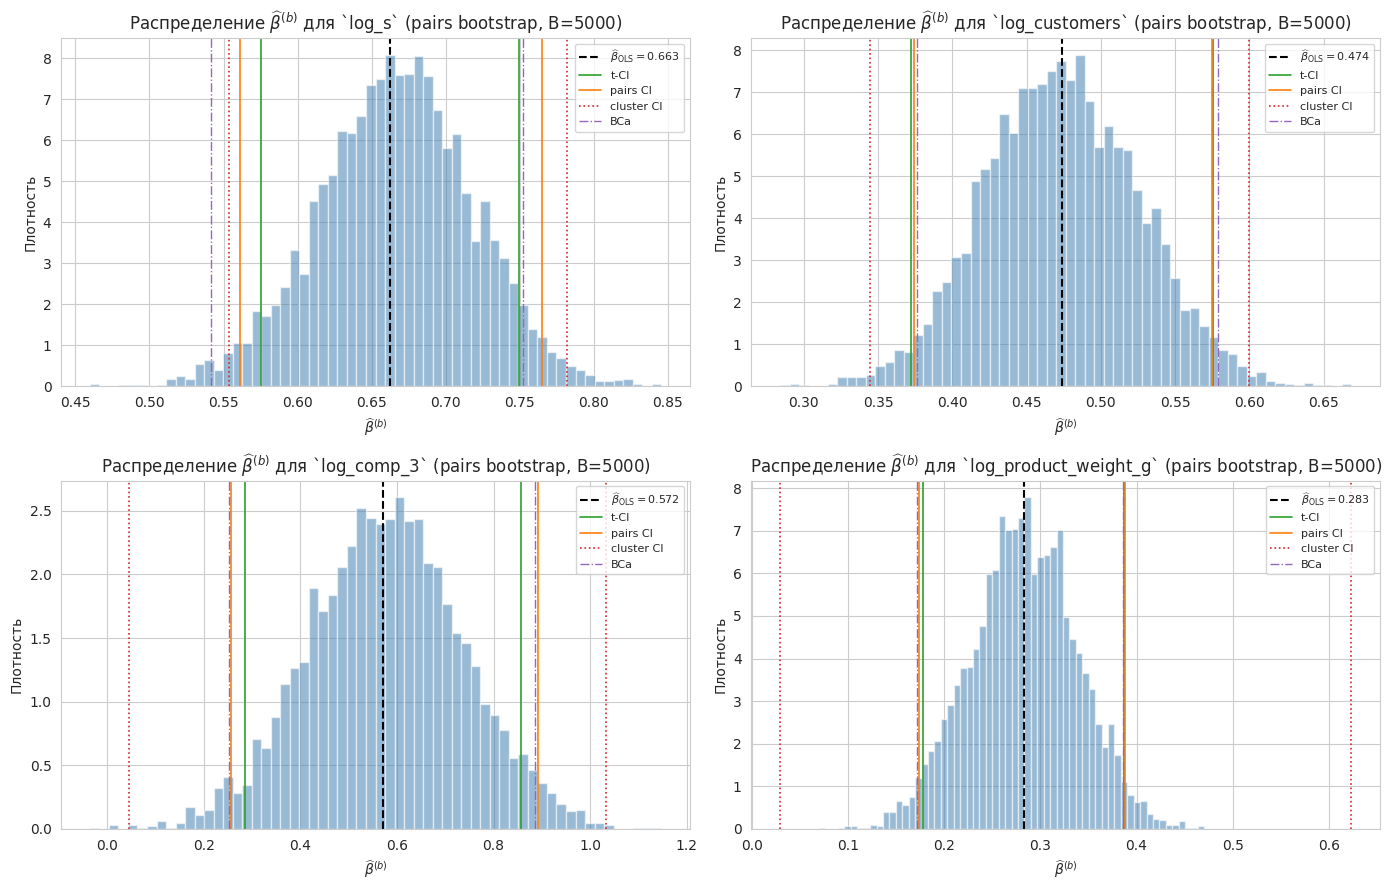

In [48]:
focus = ['log_s', 'log_customers', 'log_comp_3', 'log_product_weight_g']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, name in zip(axes.flat, focus):
    j = features_boot.index(name)
    sample = boot_pairs[:, j]
    sample = sample[~np.isnan(sample)]
    ax.hist(sample, bins=60, density=True, alpha=0.55, color='steelblue',
            edgecolor='white')
    ax.axvline(beta_ols[j], color='black', linestyle='--', lw=1.5,
               label=fr'$\widehat{{\beta}}_{{\rm OLS}} = {beta_ols[j]:.3f}$')
    ax.axvline(ci_t_arr[j, 0], color='tab:green', lw=1.2, label='t-CI')
    ax.axvline(ci_t_arr[j, 1], color='tab:green', lw=1.2)
    ax.axvline(ci_pairs[0, j], color='tab:orange', lw=1.2, label='pairs CI')
    ax.axvline(ci_pairs[1, j], color='tab:orange', lw=1.2)
    ax.axvline(ci_cluster[0, j], color='tab:red', lw=1.2, ls=':', label='cluster CI')
    ax.axvline(ci_cluster[1, j], color='tab:red', lw=1.2, ls=':')
    ax.axvline(ci_bca[0, j], color='tab:purple', lw=1.0, ls='-.', label='BCa')
    ax.axvline(ci_bca[1, j], color='tab:purple', lw=1.0, ls='-.')
    ax.set_title(fr'Распределение $\widehat{{\beta}}^{{(b)}}$ для `{name}` (pairs bootstrap, B={B_REPS})')
    ax.set_xlabel(r'$\widehat{\beta}^{(b)}$')
    ax.set_ylabel('Плотность')
    ax.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()


### VI.8. Промежуточные выводы по Главе VI

**Совпадение асимптотики и bootstrap.** Для четырёх устойчивых признаков
(`log_s`, `log_customers`, `log_comp_3`, `log_product_weight_g`)
параметрические $t$-CI, перцентильные pairs- и wild-CI, BCa-CI **попарно
почти неразличимы**. Это означает, что нормальная аппроксимация выборочного
распределения $\widehat{\beta}$ работает хорошо, несмотря на отвергнутую
в §IV.1 нормальность остатков — выручает ЦПТ при $n = 676$. Малость поправок
BCa ($|z_0|$ типично $< 0.05$, $|a|$ типично $< 0.01$) дополнительно
подтверждает симметричность и несмещённость распределения.

**Вклад cluster bootstrap.** Cluster-перцентильные CI **существенно шире**
остальных. Для четырёх устойчивых признаков они тем не менее не накрывают 0
и подтверждают значимость; для четырёх «частично устойчивых» из §V.6
(`log_volume`, `log_product_photos_qty`, `cat_garden_tools`, `cat_cool_stuff`)
cluster-CI пересекают 0 — то есть при честном учёте панельной зависимости
эти эффекты статистически неотличимы от нуля. Это **строгое подтверждение
вывода Главы V** о том, что эти сигналы недостаточно сильны, чтобы пройти
консервативный отбор.

**Сводный итог по статистическому выводу.** Из 31 исходного предиктора
**4** доказали значимость по **всем пяти** видам доверительных интервалов
(t, HC3-устойчивых из §V.1, кластерных, pairs/wild/BCa bootstrap) и **не были
обнулены Lasso**. Эти признаки — **`log_s`, `log_customers`, `log_comp_3`,
`log_product_weight_g`** — образуют ядро содержательной интерпретации
финальной модели.

**Связь с теоретической главой.** Bootstrap иллюстрирует ключевую идею
курса математической статистики: выборочное распределение оценки можно
изучать без аналитики, опираясь только на состоятельность эмпирического
распределения $\widehat{F}_n$ к $F$ (теорема Гливенко–Кантелли) и plug-in
принцип. То, что bootstrap-CI воспроизводят результаты асимптотического
вывода — практическая иллюстрация теоремы об эквивалентности этих подходов
для гладких функционалов.
